# HARPS-N exposures, SDO/HMI at the same time, and the supergranulation

For every HARPS-N solar exposure of the period (no daily average), the SDO/HMI images **closest in time**:

| image | JSOC series | used for |
|---|---|---|
| continuum intensity | `hmi.Ic_noLimbDark_720s` | identification (spots) |
| line-of-sight magnetogram | `hmi.M_45s` | identification (active pixels) |
| dopplergram | `hmi.V_720s` | velocity of the quiet photosphere |
| dopplergram, 45 s | `hmi.V_45s` | p modes during every exposure (`PMODES`) |

(MDI stopped in 2011: the dopplergrams of 2021 are HMI's.) The epochs of SDO are the 720 s records (continuum and dopplergram have the same `T_REC`); every exposure takes the closest one (≤ 6 min away when no record is missing), the magnetogram is the 45 s record closest to it.

Then, for every epoch:
1. **identification** of the spots and faculae with the thresholds below (`sunsim.sdo`, as the daily maps), projected on the cells of the SunSim grid;
2. **dopplergram**: the velocity of SDO (`OBS_VR`, `OBS_VW`, `OBS_VN`) and the rotation of the Sun (fit of a0 + a2 sin²B + a4 sin⁴B on the quiet pixels) are removed (`supergranulation.clean_dopplergram`), and the mean velocity of the quiet pixels of every cell is kept (weighted by the intensity);
3. the **FITS files are deleted** (only the filling factors and the velocities of the cells are kept, ~40 kB per epoch).

Over all the epochs: every epoch is divided by its fitted rotation relative to the mean (the HMI velocity scale changes by ~1.5 % with the velocity of SDO, `OBS_VR`); the north-south gradient of every epoch is removed (tens of m/s, it follows `OBS_VR` too: not the Sun); the mean velocity of every ring is removed (the centre-to-limb convective blueshift seen by HMI: the MURaM spectra of the grids already have their convective blueshift); a polynomial of `OBS_VR` is removed from the disc-averaged velocity (the HMI zero point follows `OBS_VR` by a few m/s, a calibration error). What is left (supergranulation, meridional flow, residual p modes, changes of the HMI zero point) is added to the quiet photosphere of every cell: `StarSim(quiet_velocity=...)` shifts the CCF of the quiet part of the cell by it.

Four simulations are compared with every HARPS-N exposure (one offset per instrumental period):
* **maps**: spots and faculae only (as before);
* **maps + dopplergram**: + the velocity of the quiet photosphere;
* **maps + dopplergram (daily fit)**: the same, with the polynomial of `OBS_VR` fitted on every day by itself.
* **maps + dopplergram + p modes**: every exposure simulated at its own time, with the p modes of the 45 s dopplergrams averaged over the exposure added to the velocity of its epoch (sections 3.1 and 4.3).

Downloads: no JSOC account is needed (the files are read from the JSOC storage, the keywords from a query). Each epoch is ~50 MB, ~2 min per thread: **start with a few days** (`DAYS`; `DAYS = None`: every day from `START` to `END`). The run can be stopped and started again: the epochs done are in `OUT/epochs` and are not downloaded again.

In [83]:
import os, json, re, time, shutil, tempfile, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sunsim import (sdo, local_path, simulate_old_config, precomputed_filling_factors, nbspectra,
                    observations as obs)
from sunsim import supergranulation as sg

# ---- parameters ------------------------------------------------------------------------------------------------
START, END = '2021-05-01', '2021-08-01'      # the period: t = 0 on START, END excluded
DAYS = ['2021-05-01', '2021-05-05', '2021-05-31']   # only these days (the two with the most exposures); None: all
SIZE = 4096                                  # pixels of the images for the identification (4096: full resolution)
N_RINGS = 30                                 # rings of the SunSim grid
THRESHOLDS = dict(noise_th=8.0, B_th=24.0, I_th=0.89, A_th=20.0, mu_area=0.1, faculae='plage')
VR_DEGREE = 2                                # polynomial of OBS_VR removed from the disc-averaged HMI velocity
MAX_DT = 15 * 60                             # [s] exposures without an SDO epoch closer than this are not used
WORKERS = 8                                  # epochs downloaded at the same time (each ~50 MB, at most 2 x WORKERS on disk)
KEEP_FITS = False                            # False: every FITS file is deleted as soon as its epoch is processed
PMODES = True                                # the p modes of every exposure from the 45 s dopplergrams (section 3.1)
DOWNLOAD_45S = False                         # False: only the 45 s frames already in FRAME_DIR (all: ~1 h per observed hour)
REF_WINDOW = 1800.0                          # [s] p modes: mean over the exposure - mean over this window centred on it
CONF = os.path.join('..', 'conf', 'starsim_sun_sdo_mps_highres.conf')   # spectra, mask, rotation of the simulation
PATHS = {'mps_folder': local_path('muram_spectra'),
         'ccf_mask': local_path('ccf_masks') / 'HARPS_G20_mps_friendly.mas'}

OUT = os.path.join('results', 'supergranulation_%s_%s' % (START, END))   # products of the epochs (small)
EPOCH_DIR = os.path.join(OUT, 'epochs')
FRAME_DIR = os.path.join(OUT, 'frames45')    # products of the 45 s dopplergrams (~10 kB per frame)
os.makedirs(EPOCH_DIR, exist_ok=True)
os.makedirs(FRAME_DIR, exist_ok=True)
print('products in', os.path.abspath(OUT))

products in /Users/sophiestucki/sunsim/analysis/results/supergranulation_2021-05-01_2021-08-01


## 1. HARPS-N exposures

Every exposure of the public release (`rv`, `fwhm`, `bis_span` and their errors); `t` = days since `START`. The times are the middle of the exposures in UTC at the Earth, from the start in `file_root` and `texp` (`jd_start`, `texp`): the `bjd` of the release is barycentric for a target in the direction of the Sun, ~500 s (1 AU / c) earlier, which matters for the p modes (and moved every exposure by ~8 min with respect to the SDO epochs before). The instrumental periods are cut at the interventions.

In [84]:
last = (pd.Timestamp(END) - pd.Timedelta(days=1)).strftime('%Y-%m-%d')
harps = obs.load_harpsn(local_path('harpsn_sun'), START, end=last, daily=False)
cuts = obs.load_interventions(local_path('harpsn_interventions'), START)
if DAYS is not None:
    wanted = [(pd.Timestamp(d) - pd.Timestamp(START)).days for d in DAYS]
    sel = np.isin(np.floor(harps['t']).astype(int), wanted)
    harps = {k: (v[sel] if isinstance(v, np.ndarray) and len(v) == len(sel) else v) for k, v in harps.items()}
day_of = np.floor(harps['t']).astype(int)
for d, n in zip(*np.unique(day_of, return_counts=True)):
    print('%s: %d exposures' % ((pd.Timestamp(START) + pd.Timedelta(days=int(d))).date(), n))
print('%d exposures on %d days; interventions in the period: %s' % (len(harps['t']), len(np.unique(day_of)),
      [str((pd.Timestamp(START) + pd.Timedelta(days=float(c))).date()) for c in cuts if 0 < c < harps['t'].max()] or 'none'))

2021-05-01: 40 exposures
2021-05-05: 98 exposures
2021-05-31: 106 exposures
244 exposures on 3 days; interventions in the period: none


## 2. The SDO epochs closest to the exposures

For every day, the records of the three series in the window of the exposures (± `MAX_DT`) are listed (`QUALITY` = 0 only). A 720 s slot is used if both the continuum and the dopplergram are good; every exposure takes the closest slot, and every slot the closest magnetogram.

In [85]:
names = {k: sg.SERIES[k][0] for k in sg.SERIES}
MATCH = os.path.join(OUT, 'matching.npz')        # the result of the queries, read back if the exposures are the same
cached = None
if os.path.exists(MATCH):
    with np.load(MATCH, allow_pickle=True) as f:
        if f['jd'].shape == harps['jd'].shape and np.array_equal(f['jd'], harps['jd']) and float(f['max_dt']) == MAX_DT:
            cached = (pd.DataFrame(json.loads(str(f['epochs']))), f['exp_trec'], f['exp_dt'])
if cached is not None:
    epochs, exp_trec, exp_dt = cached
    print('matching read from', MATCH)
else:
    epoch_of = {}                    # T_REC of the slot -> epoch
    exp_trec = np.array([None] * len(harps['t']), dtype=object)
    exp_dt = np.full(len(harps['t']), np.inf)
    for d in np.unique(day_of):
        sel = np.flatnonzero(day_of == d)
        jd0, jd1 = harps['jd'][sel].min() - MAX_DT / 86400, harps['jd'][sel].max() + MAX_DT / 86400
        rec = {k: sg.query_records(names[k], jd0, jd1) for k in names}
        slots = rec['continuum'][rec['continuum']['T_REC'].isin(rec['dopplergram']['T_REC'])].reset_index(drop=True)
        if len(slots) == 0 or len(rec['magnetogram']) == 0:
            print('day %d: no good record' % d)
            continue
        k, dt = sg.closest(harps['jd'][sel], slots['jd'].values)
        for i, kk, ddt in zip(sel, k, dt):
            if ddt > MAX_DT:
                continue
            tr = slots['T_REC'].values[kk]
            if tr not in epoch_of:
                km, dtm = sg.closest(slots['jd'].values[kk], rec['magnetogram']['jd'].values)
                epoch_of[tr] = {'continuum': tr, 'dopplergram': tr, 'magnetogram': rec['magnetogram']['T_REC'].values[km[0]],
                                'jd': slots['jd'].values[kk], 'dt_mag': dtm[0]}
            exp_trec[i], exp_dt[i] = tr, ddt

    epochs = pd.DataFrame(sorted(epoch_of.values(), key=lambda e: e['jd']))
    epochs['t'] = epochs['jd'] - obs.jd_of_date(START)
    epochs['n_exp'] = [int(np.sum(exp_trec == tr)) for tr in epochs['continuum']]
    np.savez(MATCH, jd=harps['jd'], max_dt=MAX_DT, exp_trec=exp_trec, exp_dt=exp_dt,
             epochs=epochs.to_json(orient='records', double_precision=15))
used = exp_dt <= MAX_DT
print('%d of %d exposures matched to %d SDO epochs; |dt| median %.0f s, max %.0f s; magnetogram |dt| max %.0f s'
      % (used.sum(), len(used), len(epochs), np.median(exp_dt[used]), exp_dt[used].max(), epochs['dt_mag'].max()))
print('to download: ~%.1f GB in total (deleted after every epoch), ~%.0f min with %d threads'
      % (len(epochs) * 0.049, len(epochs) * 130 / WORKERS / 60, WORKERS))
epochs.head()

matching read from results/supergranulation_2021-05-01_2021-08-01/matching.npz
240 of 244 exposures matched to 114 SDO epochs; |dt| median 184 s, max 766 s; magnetogram |dt| max 0 s
to download: ~5.6 GB in total (deleted after every epoch), ~31 min with 8 threads


,continuum,dopplergram,magnetogram,jd,dt_mag,t,n_exp
0,2021.05.01_09:12:00_TAI,2021.05.01_09:12:00_TAI,2021.05.01_09:12:00_TAI,2.459336e+06,0.0,0.382951,2
1,2021.05.01_09:24:00_TAI,2021.05.01_09:24:00_TAI,2021.05.01_09:24:00_TAI,2.459336e+06,0.0,0.391285,2
2,2021.05.01_09:48:00_TAI,2021.05.01_09:48:00_TAI,2021.05.01_09:48:00_TAI,2.459336e+06,0.0,0.407951,3
3,2021.05.01_10:24:00_TAI,2021.05.01_10:24:00_TAI,2021.05.01_10:24:00_TAI,2.459336e+06,0.0,0.432951,4
4,2021.05.01_11:00:00_TAI,2021.05.01_11:00:00_TAI,2021.05.01_11:00:00_TAI,2.459336e+06,0.0,0.457951,4


## 3. Download, identification and velocities, epoch by epoch

`WORKERS` epochs are downloaded in parallel while the previous one is processed; the three FITS files of an epoch are deleted right after it is processed (`KEEP_FITS = False`). The products of every epoch are in `OUT/epochs/<T_REC>.npz`: the epochs already there are skipped. The images of the first epoch processed are kept (1024 × 1024) for the figures.

In [86]:
def epoch_file(e):
    return os.path.join(EPOCH_DIR, re.sub(r'[^0-9]', '', e['continuum'])[:14] + '.npz')

FITS_DIR = tempfile.mkdtemp(prefix='hmi_fits_')
FRAMES = os.path.join(OUT, 'frames_first_epoch.npz')
todo = [e for e in epochs.to_dict('records') if not os.path.exists(epoch_file(e))]
print('%d epochs to do (%d already done); FITS in %s' % (len(todo), len(epochs) - len(todo), FITS_DIR))

t_start, n_bytes = time.time(), 0
for k, (e, files) in enumerate(sg.prefetch(todo, lambda e: sg.fetch_epoch(e, FITS_DIR), workers=WORKERS), 1):
    if isinstance(files, Exception):
        print('[%d/%d] %s: download failed (%s), skipped' % (k, len(todo), e['continuum'], str(files)[:100]))
        continue
    n_bytes += sum(os.path.getsize(p) for p, _ in files.values())
    try:
        r = sg.process_epoch(files, size=SIZE, n_rings=N_RINGS, thresholds=THRESHOLDS)
    except Exception as err:                                   # e.g. an image with missing data
        print('[%d/%d] %s: not processed (%s)' % (k, len(todo), e['continuum'], str(err)[:100]))
        r = None
    finally:
        if not KEEP_FITS:
            for p, _ in files.values():
                os.remove(p)
    if r is None:
        continue
    info = {key: (float(r[key]) if np.ndim(r[key]) == 0 else list(map(float, r[key])))
            for key in ('ff_sp_disc', 'ff_fc_disc', 'ff_nt_disc', 'n_spots', 'n_plages', 'omega', 'rotation',
                        'v_quiet_mean', 'obs_vr', 'B0', 'shift_px')}
    info.update({key: e[key] for key in ('continuum', 'magnetogram', 'dopplergram', 'jd', 't', 'dt_mag')})
    np.savez(epoch_file(e), ff_sp=r['ff_sp'], ff_fc=r['ff_fc'], v_cell=r['v_cell'], w_cell=r['w_cell'],
             info=json.dumps(info, default=float))
    if not os.path.exists(FRAMES):
        step = max(1, r['frames']['v'].shape[0] // 1024)
        np.savez_compressed(FRAMES, t_rec=e['continuum'], **{key: a[::step, ::step] for key, a in r['frames'].items()})
    el = time.time() - t_start
    print('[%d/%d] %s  ff_sp %.3f %%  ff_fc %.2f %%  omega %.2f deg/day  <v_quiet> %+6.1f m/s  OBS_VR %+6.0f m/s  '
          '| %.1f GB, %.0f s, ~%.0f min left' % (k, len(todo), e['continuum'], r['ff_sp_disc'], r['ff_fc_disc'],
          r['omega'], r['v_quiet_mean'], r['obs_vr'], n_bytes / 1e9, el, el / k * (len(todo) - k) / 60))
    del r
if not KEEP_FITS:
    shutil.rmtree(FITS_DIR, ignore_errors=True)
print('done: %.1f GB downloaded and deleted, %.1f min' % (n_bytes / 1e9, (time.time() - t_start) / 60))

0 epochs to do (114 already done); FITS in /var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/hmi_fits_qje4_y5a
done: 0.0 GB downloaded and deleted, 0.0 min


### 3.1 The 45 s dopplergrams (p modes)

The 720 s dopplergrams average the p modes out. For every exposure, every 45 s dopplergram (`hmi.V_45s`) within `REF_WINDOW` / 2 of its middle: the velocity of SDO is removed and the mean velocity of every cell is kept (`supergranulation.frame_cell_velocities`: all the pixels of the disc, the rotation is kept, it cancels in 4.3). One small file per frame in `OUT/frames45/<T_REC>.npz` (the frames already there are skipped), the FITS file (18 MB) deleted right after. The exposures of a day almost touch each other, so this is every frame of the observing hours: ~80 frames (1.4 GB) per hour. `DOWNLOAD_45S = False` (default): only the frames already there are used. **JSOC served ~0.4 MB/s in total in October 2026 (no gain from more threads): ~1 h per observed hour.**

In [87]:
def frame_file(t_rec):
    return os.path.join(FRAME_DIR, re.sub(r'[^0-9]', '', t_rec)[:14] + '.npz')

todo45 = []
if PMODES:
    half = (REF_WINDOW / 2 + 90) / 86400                   # + 2 frames, for the interpolation at the edges
    need = []
    for d in np.unique(day_of):
        mid = harps['jd'][day_of == d]
        rec = sg.query_records(sg.SERIES_45S[0], mid.min() - half, mid.max() + half)
        near = np.zeros(len(rec), bool)
        for m in mid:
            near |= np.abs(rec['jd'].values - m) <= half
        need += list(rec['T_REC'].values[near])
    missing = [t for t in need if not os.path.exists(frame_file(t))]
    todo45 = missing if DOWNLOAD_45S else []
    print('%d frames of 45 s, %d missing (~%.1f GB, deleted after every frame): %s'
          % (len(need), len(missing), len(missing) * 0.018, 'downloaded now' if DOWNLOAD_45S else 'not downloaded (DOWNLOAD_45S = False)'))

FITS45 = tempfile.mkdtemp(prefix='hmi45_')
t_start = time.time()
for k, (t_rec, files) in enumerate(sg.prefetch(todo45, lambda t: sg.fetch_record(sg.SERIES_45S[0], t, sg.SERIES_45S[1],
                                                                                   FITS45), workers=WORKERS), 1):
    if isinstance(files, Exception):
        print('[%d/%d] %s: download failed (%s), skipped' % (k, len(todo45), t_rec, str(files)[:100]))
        continue
    try:
        r = sg.frame_cell_velocities(files, N_RINGS)
        np.savez(frame_file(t_rec), v_cell=r['v_cell'], n_pix=r['n_pix'], jd=r['jd'], obs_vr=r['obs_vr'], t_rec=t_rec)
    except Exception as err:
        print('[%d/%d] %s: not processed (%s)' % (k, len(todo45), t_rec, str(err)[:100]))
    finally:
        if not KEEP_FITS:
            os.remove(files[0])
    if k % 50 == 0 or k == len(todo45):
        el = time.time() - t_start
        print('[%d/%d] %s  %.0f s, ~%.0f min left' % (k, len(todo45), t_rec, el, el / k * (len(todo45) - k) / 60))
if not KEEP_FITS:
    shutil.rmtree(FITS45, ignore_errors=True)

2130 frames of 45 s, 2020 missing (~36.4 GB, deleted after every frame): not downloaded (DOWNLOAD_45S = False)


## 4. The epochs

All the products read back; the exposures whose epoch could not be processed are dropped.

In [88]:
rows, arr = [], {k: [] for k in ('ff_sp', 'ff_fc', 'v_cell', 'w_cell')}
for e in epochs.to_dict('records'):
    if not os.path.exists(epoch_file(e)):
        continue
    with np.load(epoch_file(e)) as d:
        rows.append(json.loads(str(d['info'])))
        for k in arr:
            arr[k].append(d[k])
ep = pd.DataFrame(rows)
arr = {k: np.array(v) for k, v in arr.items()}
times = ep['t'].values
row_of = {tr: i for i, tr in enumerate(ep['continuum'])}
exp_epoch = np.array([row_of.get(tr, -1) for tr in exp_trec])
keep = exp_epoch >= 0
print('%d epochs, %d exposures' % (len(ep), keep.sum()))
print('rotation at the equator: %.2f +- %.2f deg/day; disc centres of continuum and dopplergram %.2f px apart (max)'
      % (ep['omega'].mean(), ep['omega'].std(), ep['shift_px'].max()))
ep[['continuum', 'magnetogram', 'ff_sp_disc', 'ff_fc_disc', 'ff_nt_disc', 'omega', 'v_quiet_mean', 'obs_vr']].head()

114 epochs, 240 exposures
rotation at the equator: 14.06 +- 0.09 deg/day; disc centres of continuum and dopplergram 0.00 px apart (max)


,continuum,magnetogram,ff_sp_disc,ff_fc_disc,ff_nt_disc,omega,v_quiet_mean,obs_vr
0,2021.05.01_09:12:00_TAI,2021.05.01_09:12:00_TAI,0.000883,0.870297,5.382814,14.183677,-17.806454,-698.858372
1,2021.05.01_09:24:00_TAI,2021.05.01_09:24:00_TAI,0.000937,0.879235,5.356055,14.152920,-17.171816,-793.188138
2,2021.05.01_09:48:00_TAI,2021.05.01_09:48:00_TAI,0.000928,0.869145,5.301009,14.143585,-16.486069,-971.397519
3,2021.05.01_10:24:00_TAI,2021.05.01_10:24:00_TAI,0.000767,0.861066,5.284879,14.090114,-15.228800,-1209.013612
4,2021.05.01_11:00:00_TAI,2021.05.01_11:00:00_TAI,0.000812,0.868974,5.246893,14.041978,-13.520721,-1405.875262


### 4.1 The velocity of the quiet photosphere

Every epoch is divided by its rotation relative to the mean (`rescale_by_rotation`), its north-south gradient is removed (`remove_large_scale`), then the mean velocity of every ring over all the epochs (weighted by the intensity of the quiet pixels) is removed, and the polynomial of `OBS_VR` that fits the disc-averaged velocity (weights: quiet intensity × limb darkening, as in the RV): `v_sg`. Below: the profile removed (the convective blueshift seen by HMI, and its zero point), and the images of the first epoch.

check of the orientation: raw velocity, west half +137 m/s, east half -1361 m/s (west must be > 0)


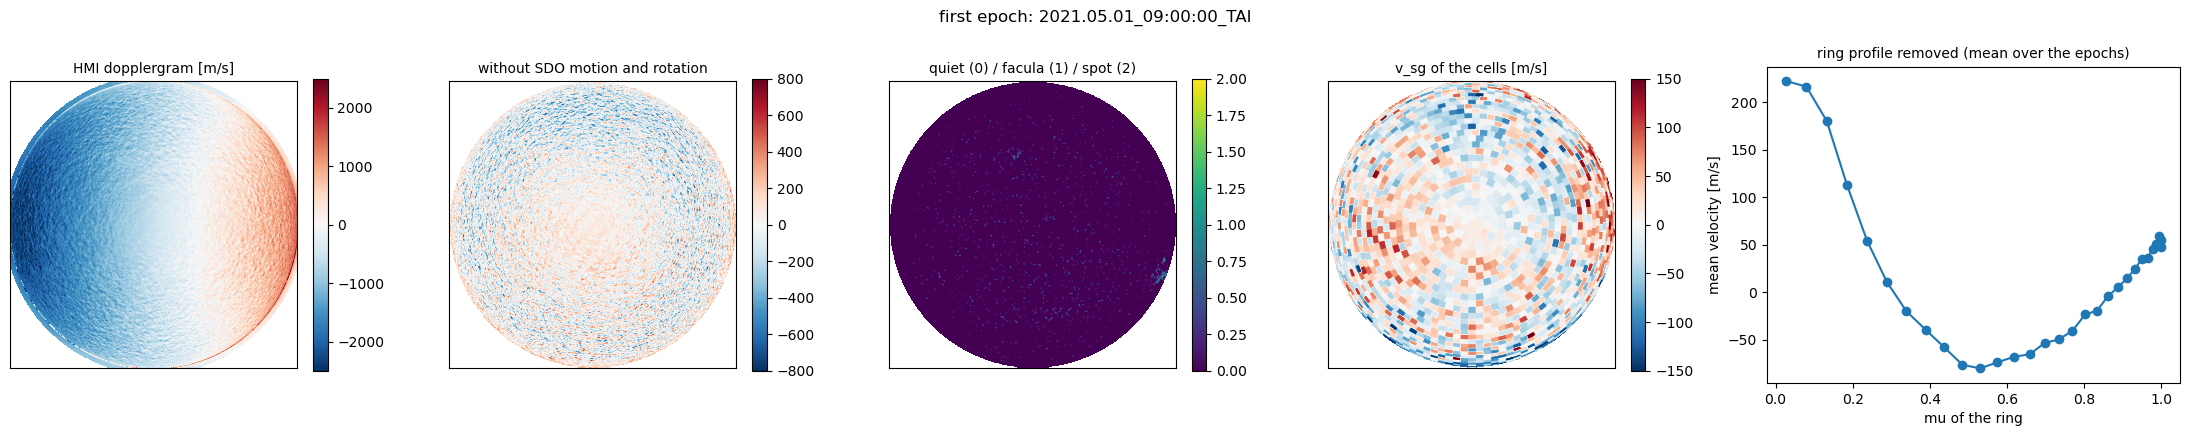

In [89]:
amu = np.asarray(nbspectra.generate_grid_coordinates_nb(N_RINGS)[3])
ring = sg.ring_of_cells(N_RINGS)
w_rv = arr['w_cell'] * (1 - 0.6 * (1 - amu))[ring]          # weight of every cell in the RV (linear limb darkening)
no_data = ~np.isfinite(arr['v_cell'])
v_scaled, scale = sg.rescale_by_rotation(arr['v_cell'], [r[0] for r in ep['rotation']])
v_flat, ns_gradient = sg.remove_large_scale(v_scaled, arr['w_cell'], N_RINGS, terms=('ns',))
v_ring, profile = sg.remove_ring_profile(v_flat, arr['w_cell'], N_RINGS)
v_sg, disc_raw, disc_sg, vr_coef = sg.remove_observer_trend(v_ring, w_rv, ep['obs_vr'].values, degree=VR_DEGREE)
v_sg[no_data] = 0.0

# the same with the polynomial of OBS_VR fitted on every day by itself (a lower degree on a day with few epochs)
ep_day = np.floor(times).astype(int)
trend_day, coef_day = np.zeros(len(times)), {}
for d in np.unique(ep_day):
    m = ep_day == d
    coef_day[d] = np.polyfit(ep['obs_vr'].values[m], disc_raw[m], min(VR_DEGREE, max(m.sum() - 2, 0)))
    trend_day[m] = np.polyval(coef_day[d], ep['obs_vr'].values[m])
v_sg_day = v_ring - trend_day[:, None]
v_sg_day[no_data] = 0.0
disc_day = disc_raw - trend_day

fr = np.load(FRAMES)
cells, _ = sdo.cell_projection(fr['v'].shape, N_RINGS)
first = row_of.get(str(fr['t_rec']), 0)
img = np.where(cells >= 0, v_sg[first][np.maximum(cells, 0)], np.nan).reshape(fr['v'].shape)
klass = np.where(fr['spot'], 2, np.where(fr['facula'], 1, 0)).astype(float)
klass[~np.isfinite(fr['v'])] = np.nan
half = fr['v_raw'].shape[1] // 2
print('check of the orientation: raw velocity, west half %+.0f m/s, east half %+.0f m/s (west must be > 0)'
      % (np.nanmean(fr['v_raw'][:, half:]), np.nanmean(fr['v_raw'][:, :half])))

fig, axes = plt.subplots(1, 5, figsize=(22, 4.4), gridspec_kw={'width_ratios': [1, 1, 1, 1, 1.3]})
for ax, a, title, kw in ((axes[0], fr['v_raw'], 'HMI dopplergram [m/s]', dict(cmap='RdBu_r', vmin=-2500, vmax=2500)),
                         (axes[1], fr['v'], 'without SDO motion and rotation', dict(cmap='RdBu_r', vmin=-800, vmax=800)),
                         (axes[2], klass, 'quiet (0) / facula (1) / spot (2)', dict(cmap='viridis', vmin=0, vmax=2)),
                         (axes[3], img, 'v_sg of the cells [m/s]', dict(cmap='RdBu_r', vmin=-150, vmax=150))):
    im = ax.imshow(a, origin='lower', **kw)
    plt.colorbar(im, ax=ax, fraction=0.046)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
axes[4].plot(amu, profile, 'o-')
axes[4].set_xlabel('mu of the ring'); axes[4].set_ylabel('mean velocity [m/s]')
axes[4].set_title('ring profile removed (mean over the epochs)', fontsize=10)
fig.suptitle('first epoch: %s' % fr['t_rec'])
plt.tight_layout()
plt.show()

### 4.2 Along the period

The rotation fitted on every dopplergram (its changes follow `OBS_VR`: the scale of the HMI velocities), the north-south gradient removed, and the disc-averaged velocity (what changes the RV at first order) before and after the `OBS_VR` trend is removed.

One row per day. The polynomial of `OBS_VR` is fitted on all the days (`v_sg`) and on every day by itself (`v_sg_day`, a second simulation in section 5): within a day `OBS_VR` changes almost monotonically, so the fit of the day also removes the slow changes of the Sun during the day.

north-south gradient: -70 to -34 m/s per radius, r = -0.99 with OBS_VR
rotation vs OBS_VR: r = 0.95 (scale 0.9902 to 1.0169); disc-averaged velocity vs OBS_VR: r = -0.95, std 2.54 m/s -> 0.56 m/s without the trend (0.48 m/s with the fit of every day)


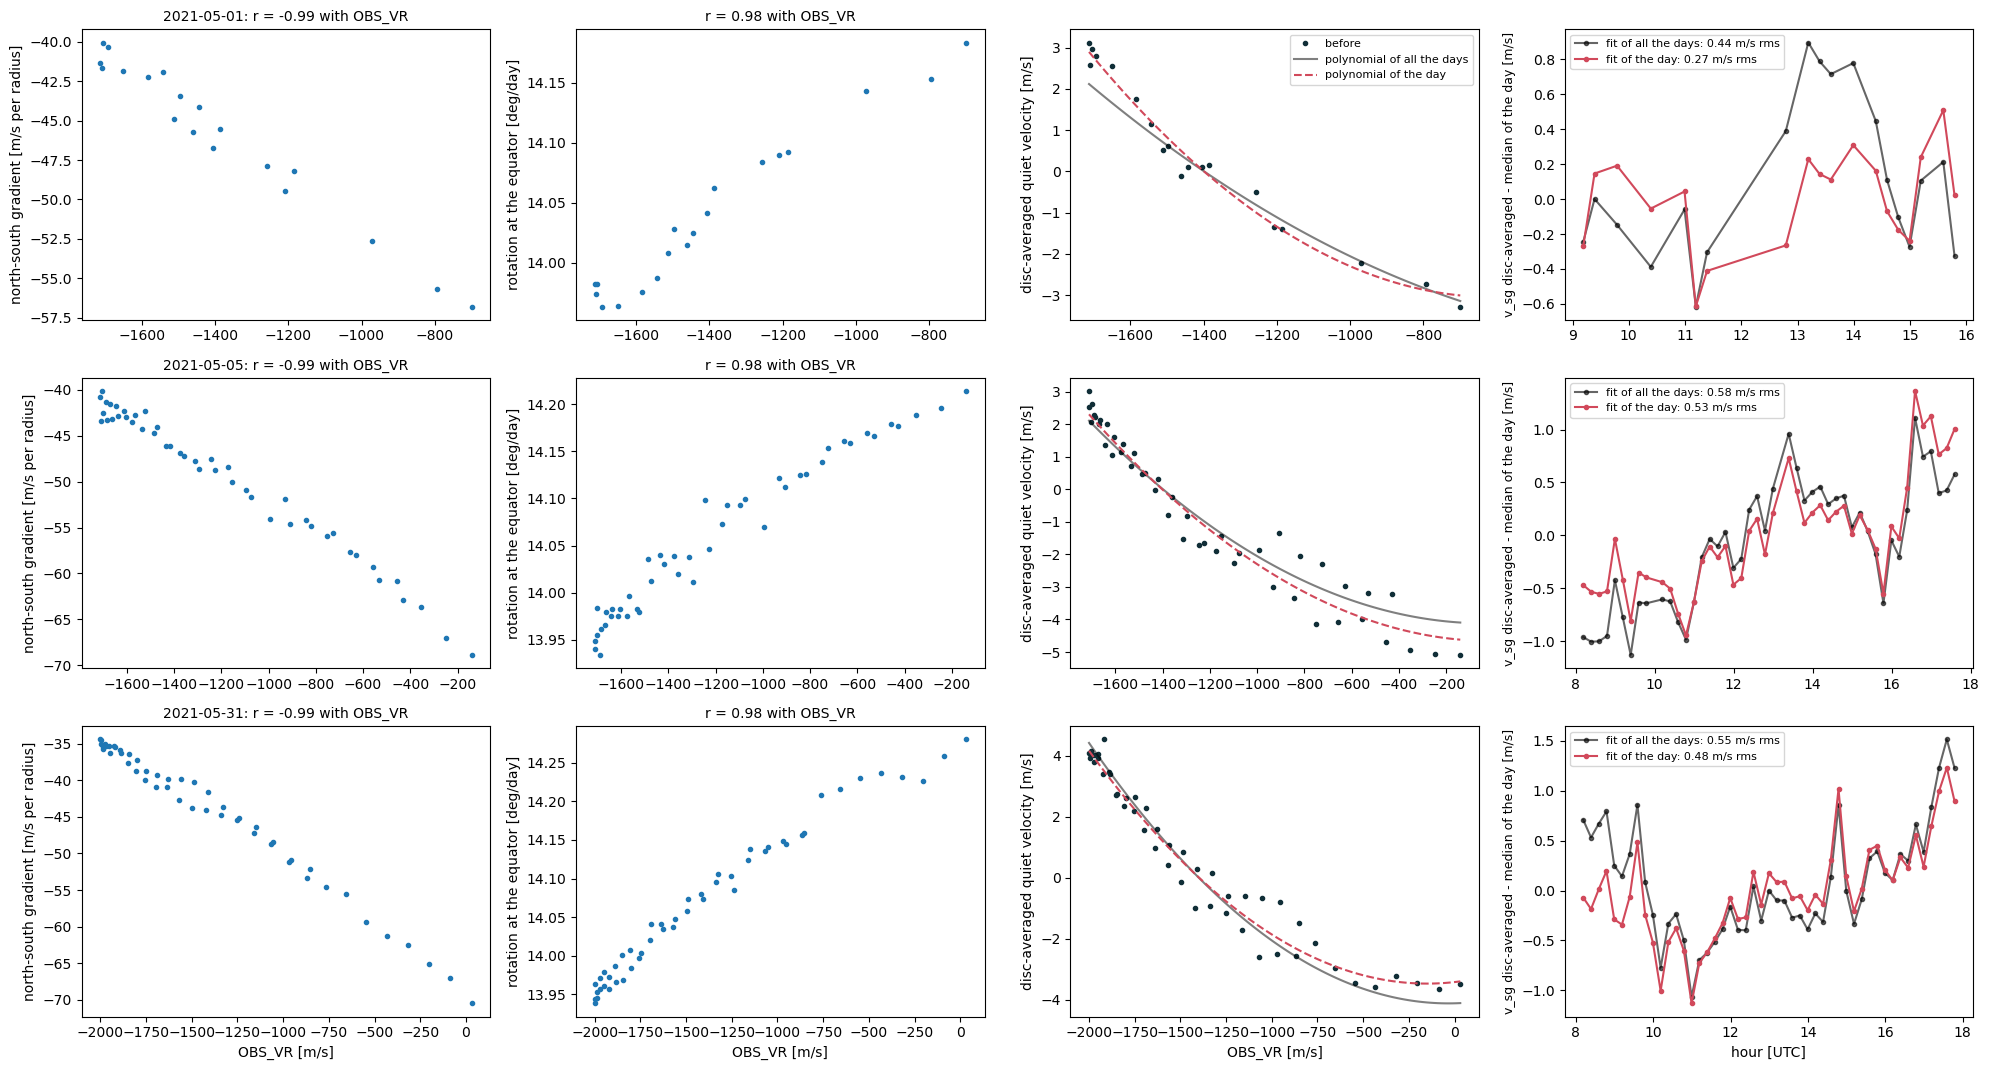

In [90]:
vr = ep['obs_vr'].values
show = np.unique(ep_day)[:12]                            # the first 12 days, as in 6.1
print('north-south gradient: %.0f to %.0f m/s per radius, r = %.2f with OBS_VR' % (ns_gradient.min(), ns_gradient.max(),
      np.corrcoef(vr, ns_gradient[:, 0])[0, 1]))
print('rotation vs OBS_VR: r = %.2f (scale %.4f to %.4f); disc-averaged velocity vs OBS_VR: r = %.2f, std %.2f m/s '
      '-> %.2f m/s without the trend (%.2f m/s with the fit of every day)' % (np.corrcoef(vr, ep['omega'])[0, 1],
      scale.min(), scale.max(), np.corrcoef(vr, disc_raw)[0, 1], np.std(disc_raw), np.std(disc_sg), np.std(disc_day)))
fig, axes = plt.subplots(len(show), 4, figsize=(20, 3.6 * len(show)), squeeze=False)
for row, d in zip(axes, show):
    m = ep_day == d
    date = (pd.Timestamp(START) + pd.Timedelta(days=int(d))).date()
    row[0].plot(vr[m], ns_gradient[m, 0], '.')
    row[0].set_ylabel('north-south gradient [m/s per radius]')
    row[0].set_title('%s: r = %.2f with OBS_VR' % (date, np.corrcoef(vr[m], ns_gradient[m, 0])[0, 1]), fontsize=10)
    row[1].plot(vr[m], ep['omega'].values[m], '.')
    row[1].set_ylabel('rotation at the equator [deg/day]')
    row[1].set_title('r = %.2f with OBS_VR' % np.corrcoef(vr[m], ep['omega'].values[m])[0, 1], fontsize=10)
    row[2].plot(vr[m], disc_raw[m], '.', color='#102e37', label='before')
    xs = np.linspace(vr[m].min(), vr[m].max(), 100)
    row[2].plot(xs, np.polyval(vr_coef, xs), 'k-', alpha=0.5, label='polynomial of all the days')
    row[2].plot(xs, np.polyval(coef_day[d], xs), '--', color='#d1495b', label='polynomial of the day')
    row[2].set_ylabel('disc-averaged quiet velocity [m/s]')
    h = (times[m] - d) * 24
    g = disc_sg[m] - np.median(disc_sg[m])
    row[3].plot(h, g, '.-', color='k', alpha=0.6, label='fit of all the days: %.2f m/s rms' % obs.rms(g))
    row[3].plot(h, disc_day[m], '.-', color='#d1495b', label='fit of the day: %.2f m/s rms' % obs.rms(disc_day[m]))
    row[3].set_ylabel('v_sg disc-averaged - median of the day [m/s]', fontsize=9)
    row[3].legend(fontsize=8)
axes[0, 2].legend(fontsize=8)
for a in axes[-1, :3]:
    a.set_xlabel('OBS_VR [m/s]')
axes[-1, 3].set_xlabel('hour [UTC]')
plt.tight_layout()
plt.show()

### 4.3 The p modes of every exposure

For every exposure, the velocity of every cell averaged over the exposure (`jd_start` to `jd_start + texp`) minus its mean over `REF_WINDOW` centred on it, from the 45 s frames (`supergranulation.pmode_velocities`, linear interpolation between the frames): the p modes and the granulation seen by HMI during the exposure. The rotation, the slow drifts of the HMI zero point and the supergranulation cancel. `v_exp = v_sg[epoch of the exposure] + delta`; the exposures whose windows are not covered by frames (a step > 100 s) keep `v_sg` (`ok45` False).

Below, one row per day: the disc-averaged velocity of the 45 s frames without its running mean over `REF_WINDOW` (weights: pixels × linear limb darkening), and its mean over every exposure.

110 frames of 45 s; p modes for 8 of 240 exposures


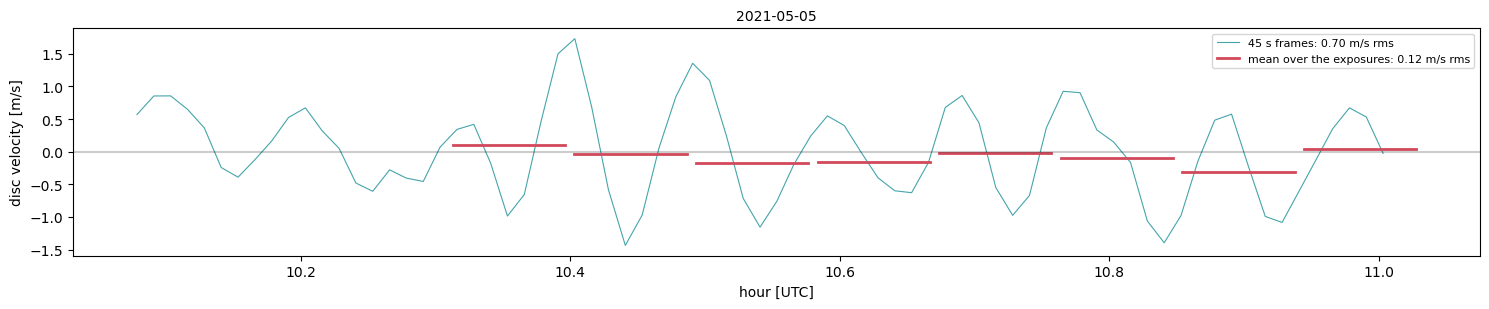

In [91]:
jd45, v45, n45 = [], [], []
for f in sorted(glob.glob(os.path.join(FRAME_DIR, '*.npz'))):
    with np.load(f) as d:
        jd45.append(float(d['jd'])); v45.append(d['v_cell']); n45.append(d['n_pix'])
jd45, v45, n45 = np.array(jd45), np.array(v45).reshape(len(jd45), -1), np.array(n45).reshape(len(jd45), -1)
e_exp = exp_epoch[keep]                                   # the epoch of every exposure kept
jd0_exp = harps['jd_start'][keep]
jd1_exp = jd0_exp + harps['texp'][keep] / 86400
if PMODES and len(jd45) > 1:
    delta, ok45 = sg.pmode_velocities(jd45, v45, jd0_exp, jd1_exp, ref_window=REF_WINDOW)
else:
    delta, ok45 = np.zeros((keep.sum(), v_sg.shape[1])), np.zeros(keep.sum(), bool)
v_exp = v_sg[e_exp] + delta
v_exp[no_data[e_exp]] = 0.0
print('%d frames of 45 s; p modes for %d of %d exposures' % (len(jd45), ok45.sum(), len(ok45)))

if np.any(ok45):
    ld = (1 - 0.6 * (1 - amu))[ring]
    w45 = np.where(np.isfinite(v45), n45 * ld, 0.0)
    disc45 = np.sum(w45 * np.nan_to_num(v45), axis=1) / np.sum(w45, axis=1)       # disc-averaged velocity of every frame
    w_cells = np.median(w45, axis=0)
    disc_delta = delta @ w_cells / w_cells.sum()                                   # disc-averaged p modes of every exposure
    d45 = np.floor(jd45 - obs.jd_of_date(START)).astype(int)
    shown = list(np.unique(day_of[keep][ok45]))
    fig, axes = plt.subplots(len(shown), 1, figsize=(15, 3.2 * len(shown)), squeeze=False)
    for ax, d in zip(axes[:, 0], shown):
        m = d45 == d
        t = (jd45[m] - jd45[m][0]) * 86400
        w, _ = sg.window_weights(t, t - REF_WINDOW / 2, t + REF_WINDOW / 2)
        hp = disc45[m] - w @ disc45[m]                                              # NaN within REF_WINDOW / 2 of the edges
        h = (jd45[m] - obs.jd_of_date(START) - d) * 24
        ax.plot(h, hp, '-', color='#45a5aa', lw=0.8, label='45 s frames: %.2f m/s rms' % np.sqrt(np.nanmean(hp ** 2)))
        me = ok45 & (day_of[keep] == d)
        for a, b, y in zip(jd0_exp[me], jd1_exp[me], disc_delta[me]):
            ax.plot((np.array([a, b]) - obs.jd_of_date(START) - d) * 24, [y, y], '-', color='#d1495b', lw=2)
        ax.plot([], [], '-', color='#d1495b', lw=2, label='mean over the exposures: %.2f m/s rms' % obs.rms(disc_delta[me]))
        ax.axhline(0, color='k', alpha=0.2)
        ax.set_ylabel('disc velocity [m/s]')
        ax.set_title(str((pd.Timestamp(START) + pd.Timedelta(days=int(d))).date()), fontsize=10)
        ax.legend(fontsize=8, loc='upper right')
    axes[-1, 0].set_xlabel('hour [UTC]')
    plt.tight_layout()
    plt.show()

## 5. Simulations

The configuration `CONF` (MURaM spectra, HARPS G2 mask, rigid rotation of 25.05 days, equator-on) with `N_RINGS` rings, from the cell filling factors of the epochs (`precomputed_filling_factors`). The grids are computed once and used by the three simulations.

In [92]:
conf = re.sub(r'(?m)^n_grid_rings\s*:\s*\d+', 'n_grid_rings : %d' % N_RINGS, open(CONF).read())
conf_file = os.path.join(OUT, 'sun_N%d.conf' % N_RINGS)
open(conf_file, 'w').write(conf)
cells_ff = precomputed_filling_factors(times, arr['ff_sp'], arr['ff_fc'], N_RINGS)
observables = ['rv', 'fwhm', 'bis', 'contrast']
t0 = time.time()
sims = {'maps': simulate_old_config(conf_file, times=times, observables=observables, paths=PATHS,
                                    active_regions_mask=cells_ff, verbose=False)}
grids = sims['maps']['grids']
for name, v in (('maps + dopplergram', v_sg), ('maps + dopplergram (daily fit)', v_sg_day)):
    sims[name] = simulate_old_config(conf_file, times=times, observables=observables, paths=PATHS, grids=grids,
                                     active_regions_mask=cells_ff, verbose=False,
                                     quiet_velocity=sg.quiet_velocity_field(times, v, N_RINGS))
print('%d simulations of %d epochs: %.0f s' % (len(sims), len(times), time.time() - t0))
for name in list(sims)[1:]:
    d = sims[name]['rv'] - sims['maps']['rv']
    print('%-32s RV change from the quiet velocity: std %.2f m/s, range %.2f m/s' % (name, np.std(d), np.ptp(d)))

# the simulation of every exposure: the one of its epoch, and with the p modes every exposure simulated at its own time
idx = exp_epoch[keep]
sims_exp = {name: {q: r[q][idx] for q in observables} for name, r in sims.items()}
if PMODES and np.any(ok45):
    t_exp = harps['t'][keep]
    ff_exp = precomputed_filling_factors(t_exp, arr['ff_sp'][idx], arr['ff_fc'][idx], N_RINGS)
    sim_pm = simulate_old_config(conf_file, times=t_exp, observables=observables, paths=PATHS, grids=grids,
                                 active_regions_mask=ff_exp, verbose=False,
                                 quiet_velocity=sg.quiet_velocity_field(t_exp, v_exp, N_RINGS))
    sims_exp['maps + dopplergram + p modes'] = {q: sim_pm[q] for q in observables}
    d = sim_pm['rv'] - sims_exp['maps + dopplergram']['rv']
    print('%-32s RV change from the p modes: std %.2f m/s on the %d exposures with them (%.1e m/s without)'
          % ('maps + dopplergram + p modes', np.std(d[ok45]), ok45.sum(), np.abs(d[~ok45]).max() if np.any(~ok45) else 0))

3 simulations of 114 epochs: 1 s
maps + dopplergram               RV change from the quiet velocity: std 0.61 m/s, range 2.91 m/s
maps + dopplergram (daily fit)   RV change from the quiet velocity: std 0.51 m/s, range 2.54 m/s
maps + dopplergram + p modes     RV change from the p modes: std 0.13 m/s on the 8 exposures with them (0.0e+00 m/s without)


## 6. Comparison with every HARPS-N exposure

Every exposure is compared with the simulation of its SDO epoch (`compare_rv_exposures`: medians removed, one offset per instrumental period, no daily average). Also: the residuals without the daily mean (`intra-day`), the part of the variability on time scales of hours, where the supergranulation should matter most.

In [93]:
hx = {k: harps[k][keep] for k in ('t', 'jd', 'rv', 'rv_err', 'fwhm', 'fwhm_err', 'bis', 'bis_err')}
# contrast: relative changes [ppm of the median] (HARPS-N gives it in % of the continuum, the simulated CCF has its own
# normalisation: only the relative changes can be compared)
def relative_ppm(x):
    return 1e6 * (np.asarray(x, dtype=np.float64) / np.nanmedian(x) - 1)
hx['contrast'] = relative_ppm(harps['contrast'][keep])
hx['contrast_err'] = 1e6 * harps['contrast_err'][keep] / np.nanmedian(harps['contrast'][keep])
cmp = {q: {name: obs.compare_rv_exposures(hx, relative_ppm(r[q]) if q == 'contrast' else r[q], quantity=q,
                                          interventions=cuts) for name, r in sims_exp.items()}
       for q in ('rv', 'fwhm', 'bis', 'contrast')}

def intra_day(t, x):
    d = np.floor(t).astype(int)
    _, inv = np.unique(d, return_inverse=True)
    return x - (np.bincount(inv, weights=x) / np.bincount(inv))[inv]

table = []
for q, by_sim in cmp.items():
    first = next(iter(by_sim.values()))
    table.append({'quantity': q, 'model': 'HARPS-N (observed)', 'RMS': first['rms_obs'], 'MAD': first['mad_obs'],
                  'RMS intra-day': obs.rms(intra_day(first['t'], first['obs']))})
    for name, c in by_sim.items():
        table.append({'quantity': q, 'model': 'obs - ' + name, 'RMS': c['rms'], 'MAD': c['mad'],
                      'RMS intra-day': obs.rms(intra_day(c['t'], c['res'])),
                      'r(obs, sim)': np.corrcoef(c['obs'], c['sim'])[0, 1]})
table = pd.DataFrame(table)
table.to_csv(os.path.join(OUT, 'statistics.csv'), index=False)
print('%d exposures [m/s; contrast: ppm of its median]' % cmp['rv']['maps']['n'])
table.round(3)

240 exposures [m/s; contrast: ppm of its median]


,quantity,model,RMS,MAD,RMS intra-day,"r(obs, sim)"
0,rv,HARPS-N (observed),0.862,0.473,0.549,NaN
1,rv,obs - maps,1.023,0.640,0.542,-0.355
2,rv,obs - maps + dopplergram,1.107,0.736,0.518,0.092
3,rv,obs - maps + dopplergram (daily fit),1.112,0.738,0.511,-0.001
4,rv,obs - maps + dopplergram + p modes,1.107,0.748,0.517,0.096
5,fwhm,HARPS-N (observed),1.470,1.087,1.433,NaN
6,fwhm,obs - maps,1.466,1.079,1.429,0.077
7,fwhm,obs - maps + dopplergram,1.455,1.015,1.422,0.197
8,fwhm,obs - maps + dopplergram (daily fit),1.455,1.016,1.423,0.195
9,fwhm,obs - maps + dopplergram + p modes,1.452,1.013,1.419,0.200


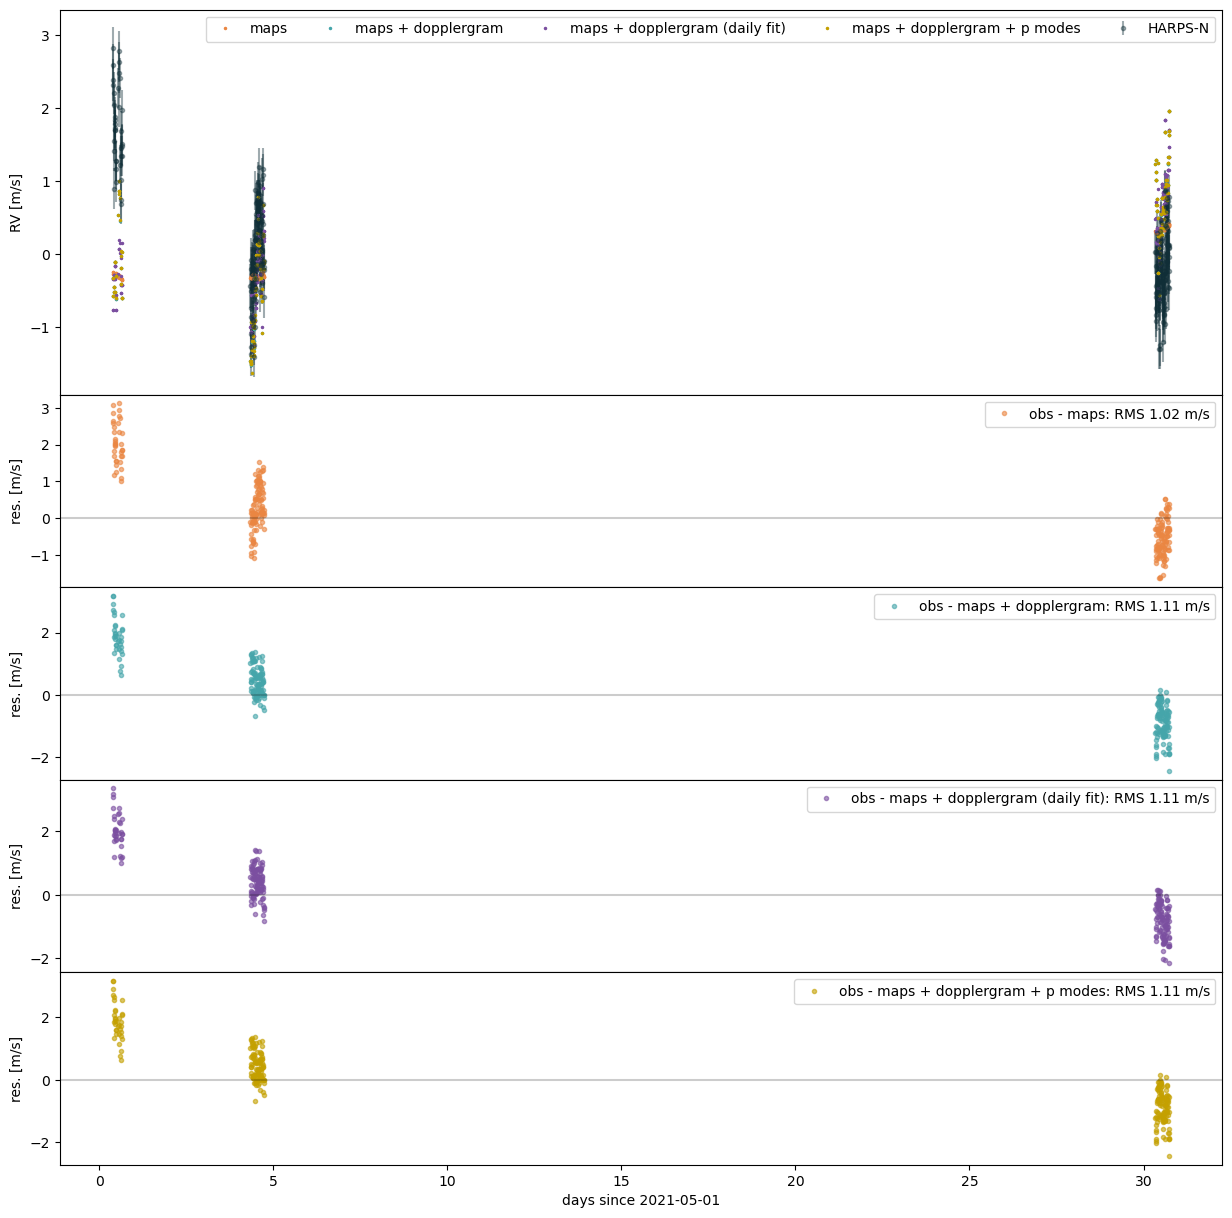

In [94]:
colours = {'maps': '#ea8642', 'maps + dopplergram': '#45a5aa', 'maps + dopplergram (daily fit)': '#7b4fa0',
           'maps + dopplergram + p modes': '#c4a000'}
models = list(cmp['rv'])
c0 = cmp['rv']['maps']
fig, axes = plt.subplots(1 + len(models), 1, figsize=(15, 5 + 2.5 * len(models)), sharex=True,
                         gridspec_kw={'hspace': 0, 'height_ratios': [2] + [1] * len(models)})
axes[0].errorbar(c0['t'], c0['obs'], yerr=c0['obs_err'], fmt='.', color='#102e37', alpha=0.4, label='HARPS-N')
for name, c in cmp['rv'].items():
    o = np.argsort(c['t'])
    axes[0].plot(c['t'][o], (c['obs'] - c['res'])[o], '.', ms=3, color=colours[name], label=name)   # sim + offsets
for a, name in zip(axes[1:], models):
    c = cmp['rv'][name]
    a.plot(c['t'], c['res'], '.', color=colours[name], alpha=0.6, label='obs - %s: RMS %.2f m/s' % (name, c['rms']))
    a.axhline(0, color='k', alpha=0.2)
    a.set_ylabel('res. [m/s]')
    a.legend(loc='upper right')
axes[0].set_ylabel('RV [m/s]')
axes[0].legend(ncols=len(models) + 1)
axes[-1].set_xlabel('days since %s' % START)
for a in axes:
    for cut in c0['interventions']:
        a.axvline(cut, color='k', alpha=0.3)
plt.show()

### 6.1 Day by day

Observed and simulated RV, FWHM, BIS and contrast of every exposure, in hours UTC, each without its median of the day (only the variations within the day are compared); in every panel, the RMS of the observations and of obs - sim (both without their median of the day). The contrast is compared as relative changes (ppm of its median): HARPS-N gives it in % of the continuum, the simulated CCF has its own normalisation.

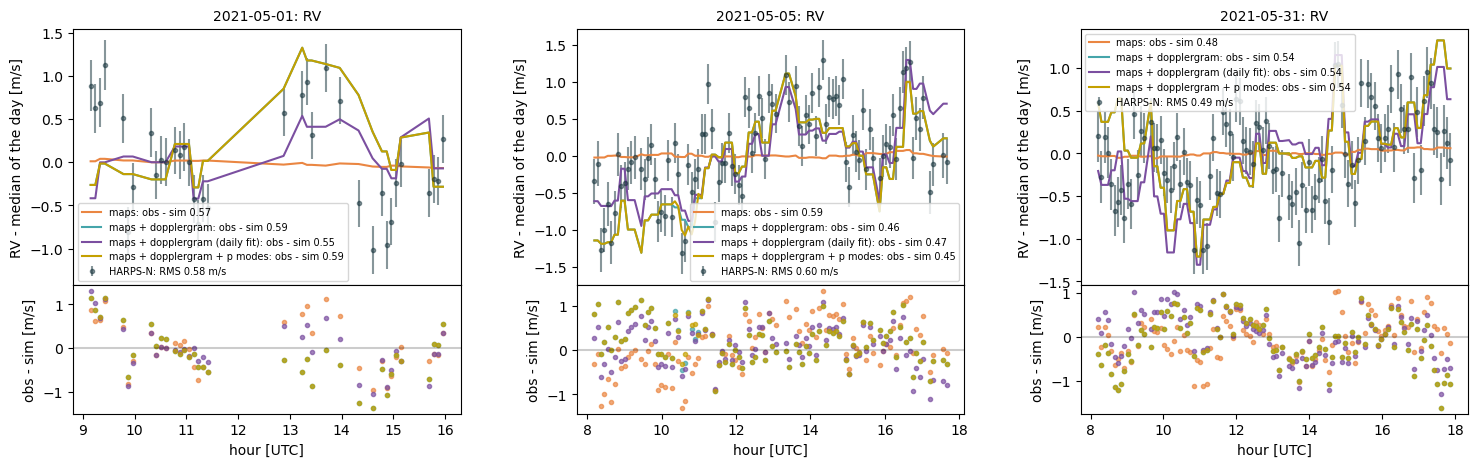

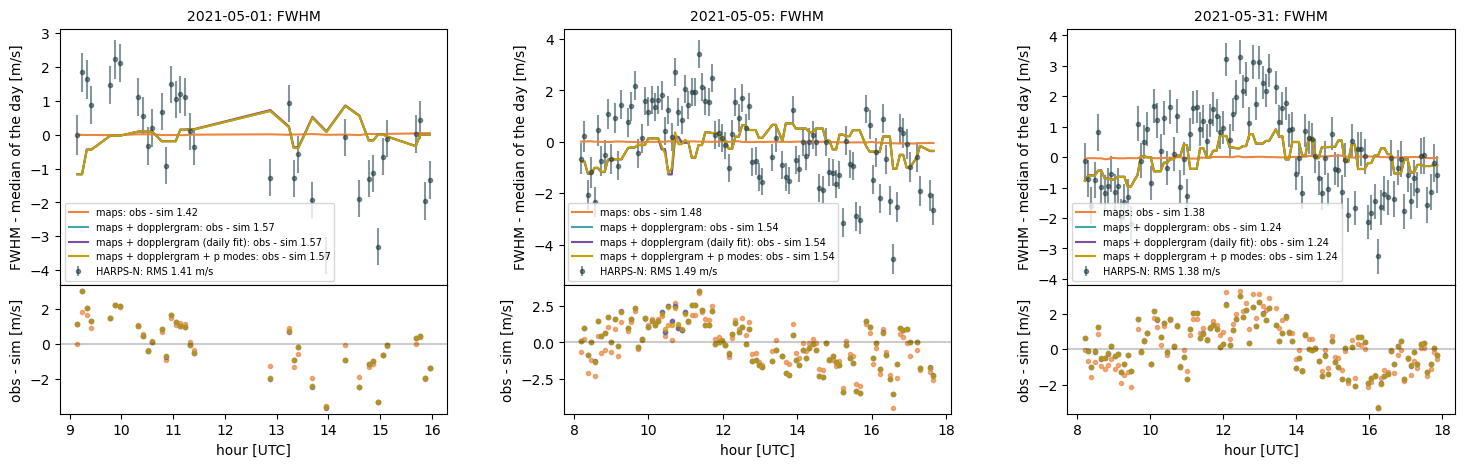

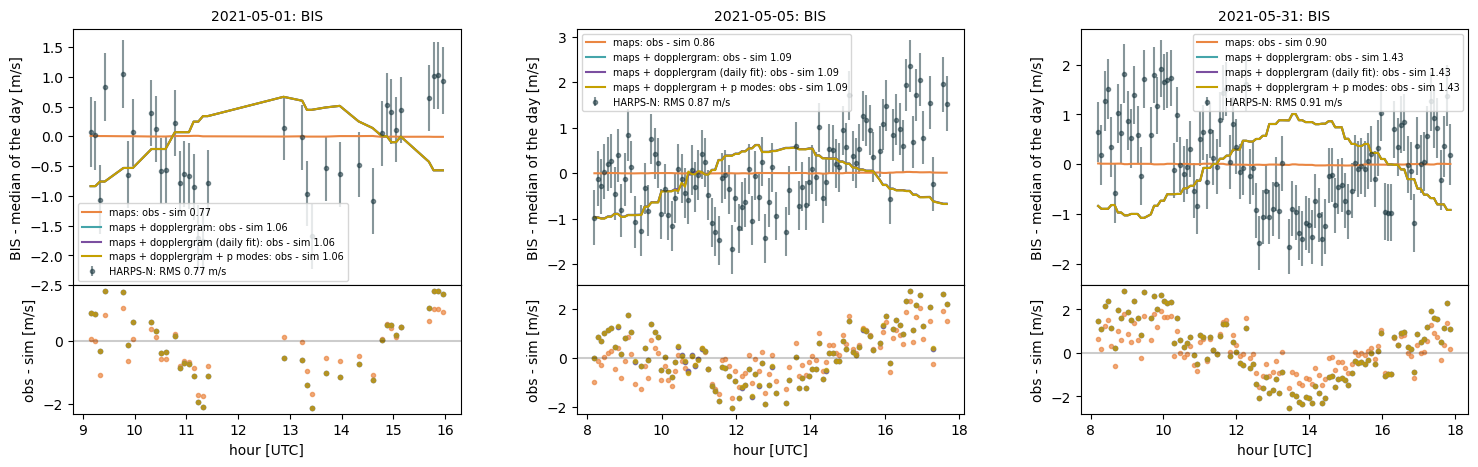

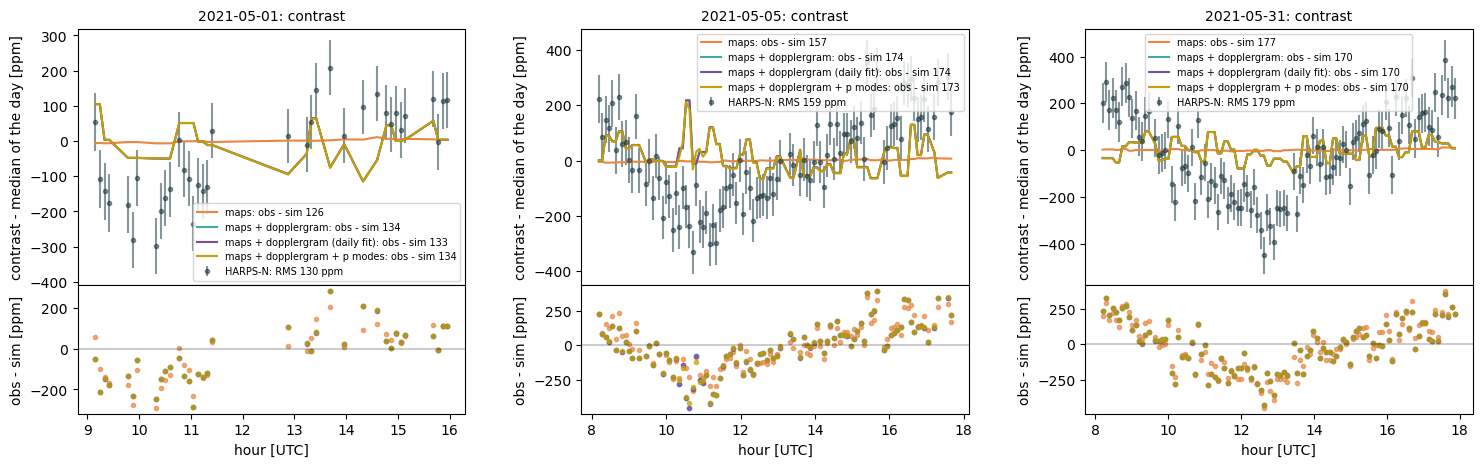

In [95]:
UNITS = {'rv': ('RV', 'm/s', '%.2f'), 'fwhm': ('FWHM', 'm/s', '%.2f'), 'bis': ('BIS', 'm/s', '%.2f'),
         'contrast': ('contrast', 'ppm', '%.0f')}

def plot_days(q, show):
    """Observed and simulated q of every exposure of the days `show`, each without its median of the day."""
    label, unit, fmt = UNITS[q]
    ncol = min(3, len(show))
    nrow = int(np.ceil(len(show) / ncol))
    fig = plt.figure(figsize=(6 * ncol, 5 * nrow))
    outer = fig.add_gridspec(nrow, ncol, hspace=0.3, wspace=0.3)
    pairs = []                                           # (value panel, residual panel) of every day
    for k in range(len(show)):
        inner = outer[k // ncol, k % ncol].subgridspec(2, 1, height_ratios=[2, 1], hspace=0)
        ax = fig.add_subplot(inner[0])
        pairs.append((ax, fig.add_subplot(inner[1], sharex=ax)))
    for (ax, ar), d in zip(pairs, show):
        for name, c in cmp[q].items():
            m = np.floor(c['t']).astype(int) == d
            h = (c['t'][m] - d) * 24
            o = c['obs'][m] - np.median(c['obs'][m])
            if name == 'maps':
                ax.errorbar(h, o, yerr=c['obs_err'][m], fmt='o', ms=3, color='#102e37', alpha=0.5,
                            label=('HARPS-N: RMS ' + fmt + ' %s') % (obs.rms(o), unit))
            s = (c['obs'] - c['res'])[m]
            s = s - np.median(s)
            ax.plot(h, s, '-', color=colours[name], label=('%s: obs - sim ' + fmt) % (name, obs.rms(o - s)))
            ar.plot(h, o - s, 'o', ms=3, color=colours[name], alpha=0.7)
        ar.axhline(0, color='k', alpha=0.2)
        ax.tick_params(labelbottom=False)
        ax.set_title('%s: %s' % ((pd.Timestamp(START) + pd.Timedelta(days=int(d))).date(), label), fontsize=10)
        ax.set_ylabel('%s - median of the day [%s]' % (label, unit))
        ax.legend(fontsize=7)
        ar.set_xlabel('hour [UTC]'); ar.set_ylabel('obs - sim [%s]' % unit)
    plt.show()

days = np.unique(np.floor(c0['t']).astype(int))
for q in ('rv', 'fwhm', 'bis', 'contrast'):
    plot_days(q, days[:12])                              # the first 12 days

In [96]:
# RMS of every day [m/s], each series without its median of the day: HARPS-N, and obs - sim for every simulation
per_day = []
for d in days:
    row = {'day': (pd.Timestamp(START) + pd.Timedelta(days=int(d))).date()}
    for name, c in cmp['rv'].items():
        m = np.floor(c['t']).astype(int) == d
        o = c['obs'][m] - np.median(c['obs'][m])
        s = (c['obs'] - c['res'])[m]
        row['n'], row['HARPS-N'] = m.sum(), obs.rms(o)
        row['obs - ' + name] = obs.rms(o - (s - np.median(s)))
    per_day.append(row)
per_day = pd.DataFrame(per_day).set_index('day')
per_day.to_csv(os.path.join(OUT, 'rms_per_day.csv'))
per_day.round(3)

,n,HARPS-N,obs - maps,obs - maps + dopplergram,obs - maps + dopplergram (daily fit),obs - maps + dopplergram + p modes
day,,,,,,
2021-05-01,36,0.575,0.569,0.595,0.554,0.595
2021-05-05,98,0.597,0.594,0.457,0.466,0.453
2021-05-31,106,0.492,0.479,0.543,0.536,0.543


### 6.2 How well does every simulation follow the observations within the day?

For every simulation, the observed values against the simulated ones (with the offsets of `compare_rv_exposures`), both without their median of every day: only the variations within the day. Pearson r and the slope of the least-squares line obs = a + slope × sim (± its standard error; 1 if the simulation has the right amplitude). The figure is the RV; the table has RV, FWHM and BIS (and the scatter of the simulation and of the observations).

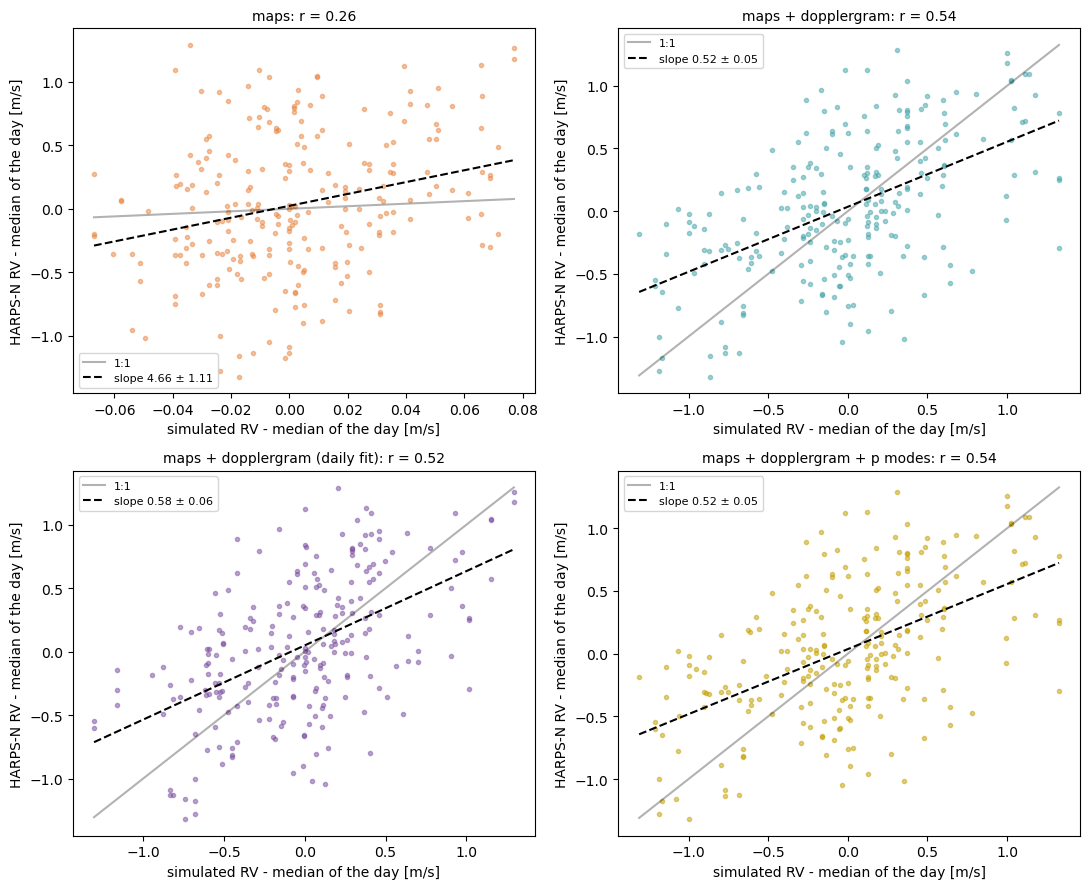

r  slope  slope_err  sim std  \
quantity model                                                             
rv       maps                            0.26   4.66       1.11     0.03   
         maps + dopplergram              0.54   0.52       0.05     0.57   
         maps + dopplergram (daily fit)  0.52   0.58       0.06     0.49   
         maps + dopplergram + p modes    0.54   0.52       0.05     0.58   
fwhm     maps                            0.16  10.06       4.01     0.02   
         maps + dopplergram              0.20   0.58       0.19     0.48   
         maps + dopplergram (daily fit)  0.19   0.57       0.19     0.48   
         maps + dopplergram + p modes    0.20   0.60       0.19     0.48   
bis      maps                            0.48  45.49       5.43     0.01   
         maps + dopplergram             -0.47  -0.72       0.09     0.57   
         maps + dopplergram (daily fit) -0.47  -0.72       0.09     0.57   
         maps + dopplergram + p modes   -0.47  -0.72       0.09     0.57   

                                         obs std  
quantity model                                    
rv       maps                               0.55  
         maps + dopplergram                 0.55  
         maps + dopplergram (daily fit)     0.55  
         maps + dopplergram + p modes       0.55  
fwhm     maps                               1.44  
         maps + dopplergram                 1.44  
         maps + dopplergram (daily fit)     1.44  
         maps + dopplergram + p modes       1.44  
bis      maps                               0.88  
         maps + dopplergram                 0.88  
         maps + dopplergram (daily fit)     0.88  
         maps + dopplergram + p modes       0.88

In [97]:
def minus_daily_median(t, x):
    """x without its median of every day."""
    d = np.floor(t).astype(int)
    out = np.array(x, dtype=np.float64)
    for dd in np.unique(d):
        m = d == dd
        out[m] -= np.median(out[m])
    return out

def fit_line(x, y):
    """Pearson r, slope and its standard error of the least-squares line y = a + slope x."""
    x, y = x - np.mean(x), y - np.mean(y)
    slope = np.sum(x * y) / np.sum(x * x)
    err = np.sqrt(np.sum((y - slope * x) ** 2) / (len(x) - 2) / np.sum(x * x))
    return np.corrcoef(x, y)[0, 1], slope, err

fits = []
for q in ('rv', 'fwhm', 'bis'):
    for name, cq in cmp[q].items():
        x = minus_daily_median(cq['t'], cq['obs'] - cq['res'])            # simulation (+ offsets) - median of the day
        y = minus_daily_median(cq['t'], cq['obs'])
        r, k, k_err = fit_line(x, y)
        fits.append({'quantity': q, 'model': name, 'r': r, 'slope': k, 'slope_err': k_err,
                     'sim std': np.std(x), 'obs std': np.std(y), 'n': len(x)})
fits = pd.DataFrame(fits)
fits.to_csv(os.path.join(OUT, 'correlations_intra_day.csv'), index=False)

ncol = min(2, len(models))
nrow = int(np.ceil(len(models) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(5.5 * ncol, 4.5 * nrow), squeeze=False)
for ax, name in zip(axes.ravel(), models):
    cq = cmp['rv'][name]
    x = minus_daily_median(cq['t'], cq['obs'] - cq['res'])
    y = minus_daily_median(cq['t'], cq['obs'])
    f = fits[(fits['quantity'] == 'rv') & (fits['model'] == name)].iloc[0]
    ax.plot(x, y, '.', color=colours[name], alpha=0.5)
    xs = np.array([x.min(), x.max()])
    ax.plot(xs, xs, 'k-', alpha=0.3, label='1:1')
    ax.plot(xs, np.mean(y) + f['slope'] * (xs - np.mean(x)), '--', color='k',
            label='slope %.2f ± %.2f' % (f['slope'], f['slope_err']))
    ax.set_xlabel('simulated RV - median of the day [m/s]')
    ax.set_ylabel('HARPS-N RV - median of the day [m/s]')
    ax.set_title('%s: r = %.2f' % (name, f['r']), fontsize=10)
    ax.legend(fontsize=8)
for ax in axes.ravel()[len(models):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

c = cmp['rv']['maps']                                                     # for the table of the exposures below
fin = np.isfinite(hx['rv']) & np.isfinite(sims_exp['maps']['rv'])        # the exposures of compare_rv_exposures
fits.set_index(['quantity', 'model'])[['r', 'slope', 'slope_err', 'sim std', 'obs std']].round(2)

### 6.3 Do the p modes of the 45 s dopplergrams explain the residuals?

On the exposures with the p modes (`ok45`): the RV they add (`maps + dopplergram + p modes` − `maps + dopplergram`) against the residual without them (`obs − maps + dopplergram`), its correlation, and the factor that fits it best (1 if HMI and the CCF see the same p modes; the lines of the mask form at other heights than Fe I 6173). The 5 min exposures of HARPS-N were chosen to average the p modes: what is left is small next to the granulation, so many exposures are needed to see it (4.3 gives its size).

8 exposures: p modes 0.13 m/s rms; r = 0.62 with obs - maps + dopplergram (intra-day); best factor 2.11 +- 1.00; RMS intra-day 0.447 -> 0.380 m/s with them


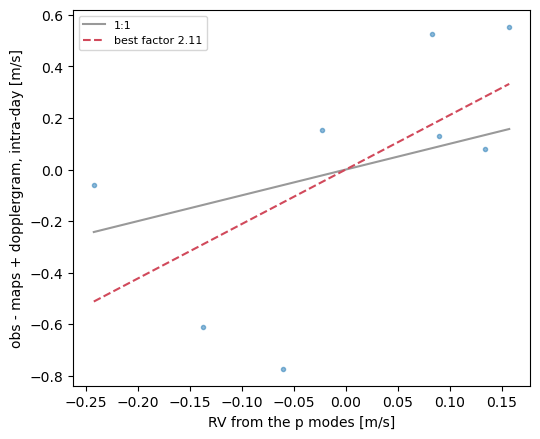

In [98]:
if 'maps + dopplergram + p modes' in sims_exp:
    base = 'maps + dopplergram'
    fin = np.isfinite(hx['rv']) & np.isfinite(sims_exp[base]['rv'])     # the exposures of compare_rv_exposures, in order
    pm = (sims_exp['maps + dopplergram + p modes']['rv'] - sims_exp[base]['rv'])[fin]
    res = cmp['rv'][base]['res']
    m = ok45[fin]
    x, y = pm[m], intra_day(cmp['rv'][base]['t'][m], res[m])
    x = x - np.mean(x)
    k = np.sum(x * y) / np.sum(x * x)
    k_err = np.sqrt(np.sum((y - k * x) ** 2) / (len(x) - 1) / np.sum(x * x))
    rms_with = obs.rms(intra_day(cmp['rv'][base]['t'][m], res[m] - pm[m]))
    print('%d exposures: p modes %.2f m/s rms; r = %.2f with obs - %s (intra-day); best factor %.2f +- %.2f; '
          'RMS intra-day %.3f -> %.3f m/s with them' % (m.sum(), np.std(x), np.corrcoef(x, y)[0, 1], base, k, k_err,
                                                      obs.rms(y), rms_with))
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    ax.plot(x, y, '.', alpha=0.5)
    xs = np.array([x.min(), x.max()])
    ax.plot(xs, xs, 'k-', alpha=0.4, label='1:1')
    ax.plot(xs, k * xs, '--', color='#d1495b', label='best factor %.2f' % k)
    ax.set_xlabel('RV from the p modes [m/s]')
    ax.set_ylabel('obs - %s, intra-day [m/s]' % base)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

### 6.4 Daily averages

The RV of every day averaged over its exposures: HARPS-N and every simulation (with the offsets of `compare_rv_exposures`, one for all the days), how much the velocity of the quiet photosphere changes the mean of the day (`maps + dopplergram` − `maps`) next to its scatter within the day, and the RMS of obs − sim on the daily means (one common offset removed). The daily mean of the dopplergram depends on the zero point of HMI (the polynomial of `OBS_VR` is fitted on a few days only): the least reliable part of it.

maps                             daily means: obs - sim RMS 1.074 m/s (HARPS-N alone 0.871 m/s)
maps + dopplergram               daily means: obs - sim RMS 1.131 m/s (HARPS-N alone 0.871 m/s)
maps + dopplergram (daily fit)   daily means: obs - sim RMS 1.173 m/s (HARPS-N alone 0.871 m/s)
maps + dopplergram + p modes     daily means: obs - sim RMS 1.131 m/s (HARPS-N alone 0.871 m/s)
the dopplergram changes the daily mean by 0.24 m/s rms, 0.54 m/s rms within the day


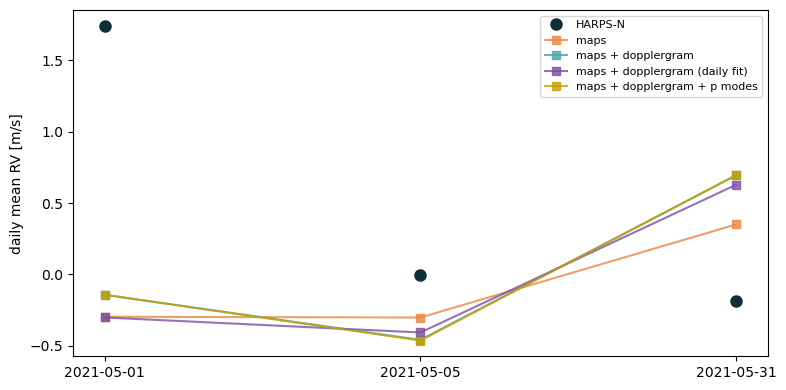

,n,HARPS-N,maps,maps + dopplergram,maps + dopplergram (daily fit),maps + dopplergram + p modes,dopplergram - maps,its std within the day
day,,,,,,,,
2021-05-01,36,1.742,-0.297,-0.144,-0.302,-0.142,0.153,0.496
2021-05-05,98,-0.006,-0.302,-0.459,-0.407,-0.464,-0.156,0.609
2021-05-31,106,-0.190,0.350,0.695,0.628,0.696,0.345,0.516


In [99]:
c_ref = cmp['rv']['maps']
day_c = np.floor(c_ref['t']).astype(int)
daily = []
for d in np.unique(day_c):
    m = day_c == d
    row = {'day': (pd.Timestamp(START) + pd.Timedelta(days=int(d))).date(), 'n': int(m.sum()),
           'HARPS-N': c_ref['obs'][m].mean()}
    for name, cq in cmp['rv'].items():
        row[name] = (cq['obs'] - cq['res'])[m].mean()                       # simulation + offsets
    dv = (cmp['rv']['maps + dopplergram']['obs'] - cmp['rv']['maps + dopplergram']['res'])[m] - (c_ref['obs'] - c_ref['res'])[m]
    row['dopplergram - maps'] = dv.mean()
    row['its std within the day'] = dv.std()
    daily.append(row)
daily = pd.DataFrame(daily).set_index('day')
daily.to_csv(os.path.join(OUT, 'rv_daily_means.csv'))

for name in cmp['rv']:
    res = daily['HARPS-N'] - daily[name]
    res = res - res.mean()                                                   # one common offset for all the days
    print('%-32s daily means: obs - sim RMS %.3f m/s (HARPS-N alone %.3f m/s)'
          % (name, np.sqrt(np.mean(res ** 2)), np.std(daily['HARPS-N'])))
print('the dopplergram changes the daily mean by %.2f m/s rms, %.2f m/s rms within the day'
      % (np.sqrt(np.mean(daily['dopplergram - maps'] ** 2)), np.sqrt(np.mean(daily['its std within the day'] ** 2))))

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(daily))
ax.plot(x, daily['HARPS-N'], 'o', color='#102e37', ms=8, label='HARPS-N')
for name in cmp['rv']:
    ax.plot(x, daily[name], 's-', color=colours[name], alpha=0.8, label=name)
ax.set_xticks(x)
ax.set_xticklabels([str(d) for d in daily.index])
ax.set_ylabel('daily mean RV [m/s]')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
daily.round(3)

In [100]:
# every exposure and the simulations
out = pd.DataFrame({'jd_utc': hx['jd'][fin], 't': c['t'], 'sdo_t_rec': exp_trec[keep][fin], 'dt_sdo_s': exp_dt[keep][fin],
                    'rv_obs': c['obs'], 'rv_err': c['obs_err']})
for name, cc in cmp['rv'].items():
    out['rv_' + name.replace(' + ', '_').replace(' ', '_').replace('(', '').replace(')', '').replace('.', '')] = cc['obs'] - cc['res']
out.to_csv(os.path.join(OUT, 'exposures.csv'), index=False)
ep.to_csv(os.path.join(OUT, 'epochs.csv'), index=False)
print('written:', os.path.join(OUT, 'exposures.csv'), os.path.join(OUT, 'epochs.csv'), os.path.join(OUT, 'statistics.csv'))

written: results/supergranulation_2021-05-01_2021-08-01/exposures.csv results/supergranulation_2021-05-01_2021-08-01/epochs.csv results/supergranulation_2021-05-01_2021-08-01/statistics.csv


## 7. Test on 2021-05-05: full resolution, 60 rings, network as quiet Sun or as faculae

The SDO epochs of `TEST_DAY` processed again (`process_epoch`, images of 4096 × 4096 pixels) for a grid of `TEST_RINGS` = 60 rings, with two thresholds of area:
* **A_th = 20 µhem** (as above): the bright groups smaller than this are network, counted as quiet photosphere (their velocity is in the quiet velocity of the cell);
* **A_th = 0**: every bright group is plage, so all the network is facula (and is not in the quiet velocity).

Every epoch is downloaded once and processed for the two cases (FITS deleted right after, at most two epochs on disk); the products are in `OUT/test_<day>_N60/<case>/` and the epochs already there are skipped. The velocities are calibrated as in 4.1 over the epochs of the day, with the polynomial of `OBS_VR` of 4.1 (fitted on all the days at 30 rings: the zero point of HMI does not depend on the grid). Every exposure of the day is simulated at its own time, maps alone and maps + dopplergram, and compared with HARPS-N (median of the day removed), together with the simulations at 30 rings of section 5.

In [101]:
TEST_DAY = '2021-05-05'
TEST_RINGS = 60
TEST_CASES = {'A_th = 20': ('Ath20', dict(THRESHOLDS, A_th=20.0)),          # network = quiet photosphere
              'A_th = 0': ('Ath0', dict(THRESHOLDS, A_th=0.0))}             # all the network = faculae
TEST_DIR = os.path.join(OUT, 'test_%s_N%d' % (TEST_DAY, TEST_RINGS))
for tag, _ in TEST_CASES.values():
    os.makedirs(os.path.join(TEST_DIR, tag), exist_ok=True)
d_test = (pd.Timestamp(TEST_DAY) - pd.Timestamp(START)).days
ep_test = ep[np.floor(ep['t']).astype(int) == d_test].reset_index(drop=True)    # the SDO epochs of the day (section 4)

def test_file(tag, e):
    return os.path.join(TEST_DIR, tag, re.sub(r'[^0-9]', '', e['continuum'])[:14] + '.npz')

todo_t = [e for e in ep_test.to_dict('records') if not all(os.path.exists(test_file(tag, e)) for tag, _ in TEST_CASES.values())]
print('%s: %d epochs, %d to do (~%.1f GB, deleted after every epoch)' % (TEST_DAY, len(ep_test), len(todo_t), len(todo_t) * 0.05))
FITS_T = tempfile.mkdtemp(prefix='hmi_test_')
t_start = time.time()
for k, (e, files) in enumerate(sg.prefetch(todo_t, lambda e: sg.fetch_epoch(e, FITS_T), workers=1, ahead=1), 1):
    if isinstance(files, Exception):
        print('[%d/%d] %s: download failed (%s), skipped' % (k, len(todo_t), e['continuum'], str(files)[:100]))
        continue
    try:
        for case, (tag, th) in TEST_CASES.items():
            if os.path.exists(test_file(tag, e)):
                continue
            r = sg.process_epoch(files, size=SIZE, n_rings=TEST_RINGS, thresholds=th)
            np.savez(test_file(tag, e), ff_sp=r['ff_sp'], ff_fc=r['ff_fc'], v_cell=r['v_cell'], w_cell=r['w_cell'],
                     rotation=r['rotation'], obs_vr=r['obs_vr'], ff_sp_disc=r['ff_sp_disc'], ff_fc_disc=r['ff_fc_disc'],
                     ff_nt_disc=r['ff_nt_disc'], t=e['t'], t_rec=e['continuum'])
            del r
    except Exception as err:
        print('[%d/%d] %s: not processed (%s)' % (k, len(todo_t), e['continuum'], str(err)[:100]))
    finally:
        if not KEEP_FITS:
            for p, _ in files.values():
                os.remove(p)
    if k % 5 == 0 or k == len(todo_t):
        el = time.time() - t_start
        print('[%d/%d] %s  %.0f s, ~%.0f min left' % (k, len(todo_t), e['continuum'], el, el / k * (len(todo_t) - k) / 60))
if not KEEP_FITS:
    shutil.rmtree(FITS_T, ignore_errors=True)

2021-05-05: 46 epochs, 0 to do (~0.0 GB, deleted after every epoch)


A_th = 20: faculae 0.84 % of the disc (network not in them: 5.30 %)
A_th = 0: faculae 6.15 % of the disc (network not in them: 0.00 %)


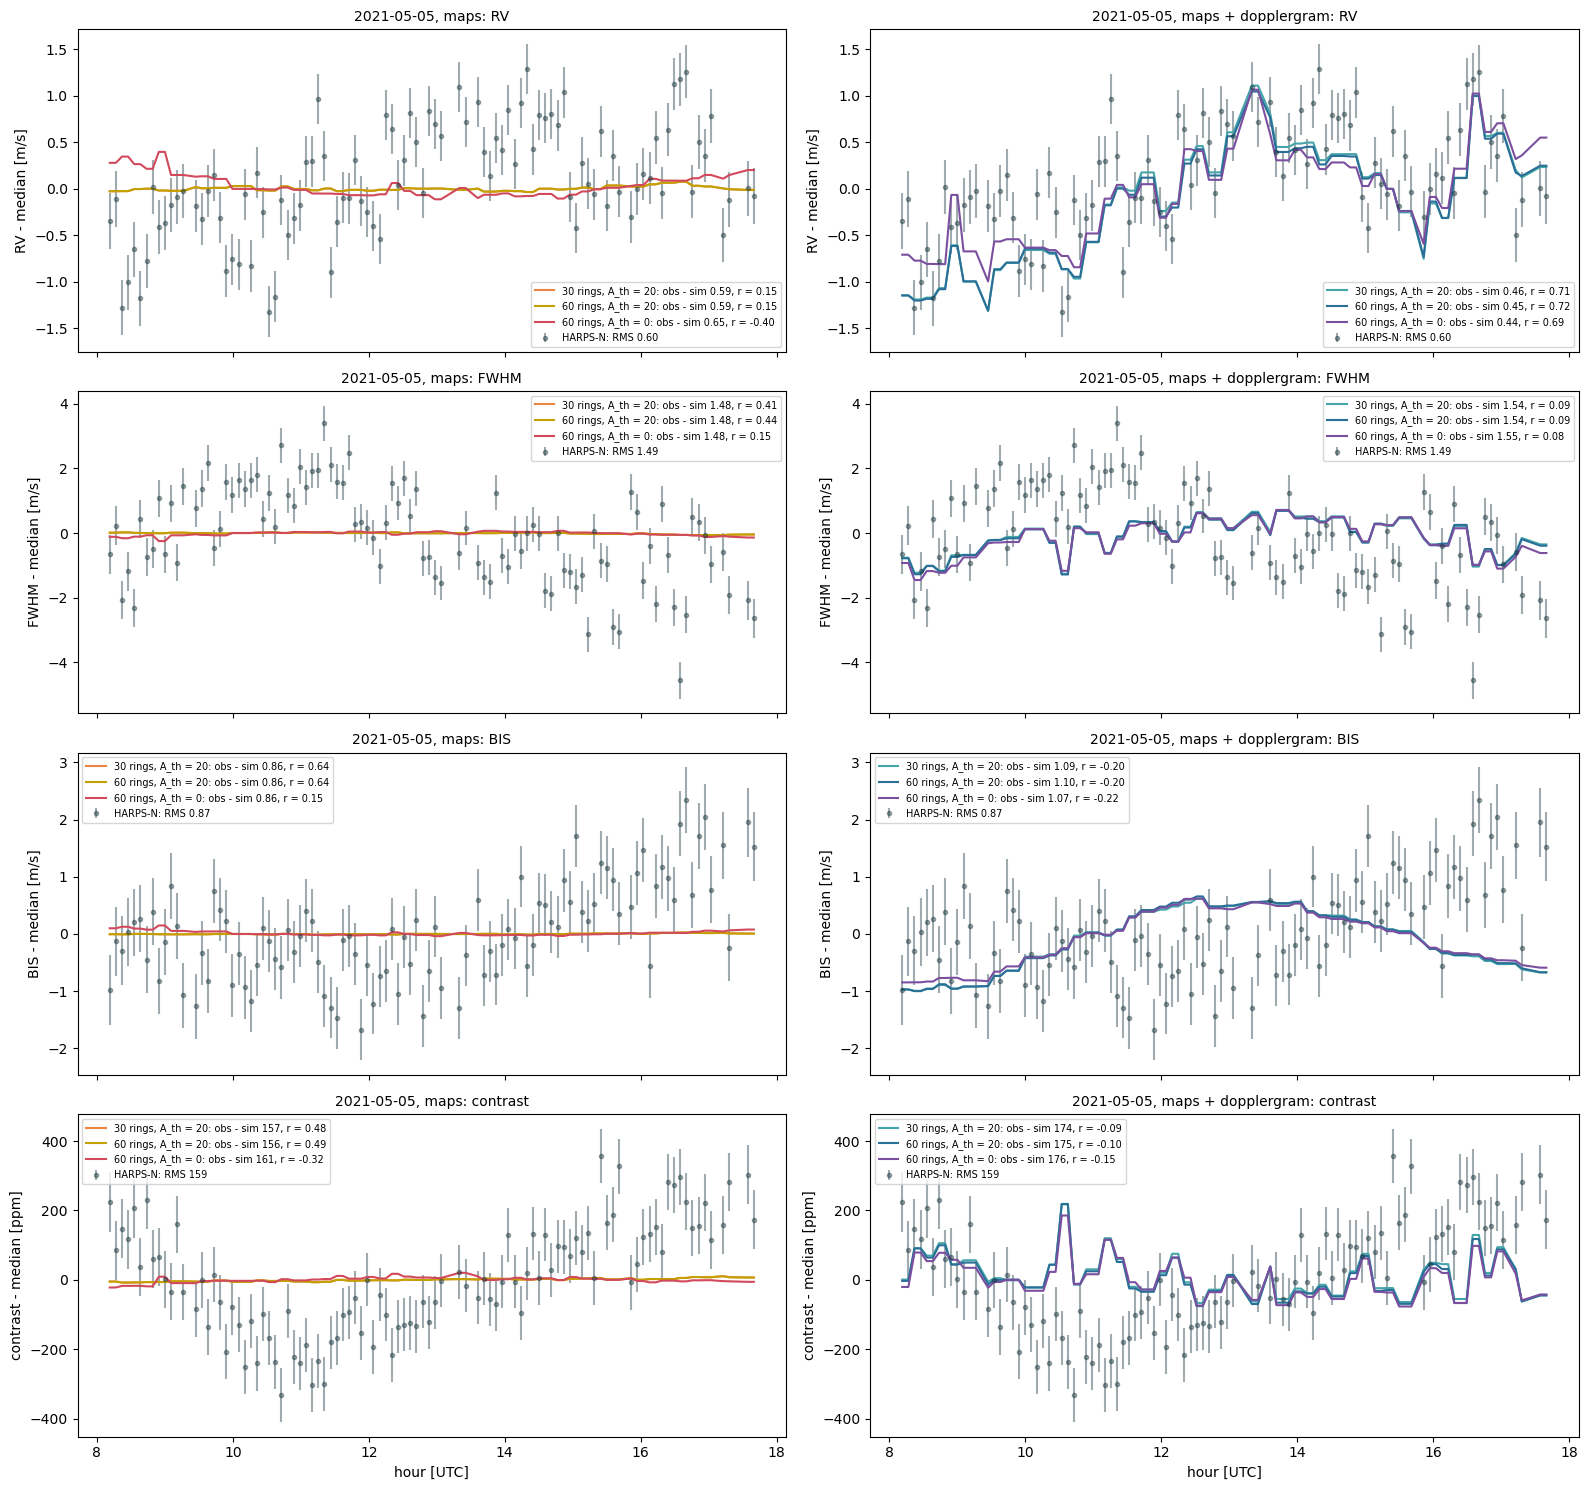

RMS obs  RMS obs - sim  \
quantity model                                                             
rv       30 rings, A_th = 20: maps                  0.597          0.594   
         30 rings, A_th = 20: maps + dopplergram    0.597          0.457   
         60 rings, A_th = 20: maps                  0.597          0.594   
         60 rings, A_th = 20: maps + dopplergram    0.597          0.450   
         60 rings, A_th = 0: maps                   0.597          0.654   
         60 rings, A_th = 0: maps + dopplergram     0.597          0.440   
fwhm     30 rings, A_th = 20: maps                  1.491          1.482   
         30 rings, A_th = 20: maps + dopplergram    1.491          1.542   
         60 rings, A_th = 20: maps                  1.491          1.481   
         60 rings, A_th = 20: maps + dopplergram    1.491          1.540   
         60 rings, A_th = 0: maps                   1.491          1.482   
         60 rings, A_th = 0: maps + dopplergram     1.491          1.551   
bis      30 rings, A_th = 20: maps                  0.869          0.864   
         30 rings, A_th = 20: maps + dopplergram    0.869          1.094   
         60 rings, A_th = 20: maps                  0.869          0.864   
         60 rings, A_th = 20: maps + dopplergram    0.869          1.099   
         60 rings, A_th = 0: maps                   0.869          0.864   
         60 rings, A_th = 0: maps + dopplergram     0.869          1.073   
contrast 30 rings, A_th = 20: maps                158.519        156.533   
         30 rings, A_th = 20: maps + dopplergram  158.519        174.179   
         60 rings, A_th = 20: maps                158.519        156.449   
         60 rings, A_th = 20: maps + dopplergram  158.519        175.077   
         60 rings, A_th = 0: maps                 158.519        161.339   
         60 rings, A_th = 0: maps + dopplergram   158.519        175.862   

                                                      r   slope  slope_err  \
quantity model                                                               
rv       30 rings, A_th = 20: maps                0.146   3.530      2.444   
         30 rings, A_th = 20: maps + dopplergram  0.714   0.698      0.070   
         60 rings, A_th = 20: maps                0.154   3.645      2.383   
         60 rings, A_th = 20: maps + dopplergram  0.717   0.716      0.071   
         60 rings, A_th = 0: maps                -0.397  -1.987      0.469   
         60 rings, A_th = 0: maps + dopplergram   0.692   0.823      0.088   
fwhm     30 rings, A_th = 20: maps                0.406  27.182      6.243   
         30 rings, A_th = 20: maps + dopplergram  0.086   0.237      0.280   
         60 rings, A_th = 20: maps                0.444  28.804      5.925   
         60 rings, A_th = 20: maps + dopplergram  0.087   0.241      0.282   
         60 rings, A_th = 0: maps                 0.152   3.447      2.283   
         60 rings, A_th = 0: maps + dopplergram   0.084   0.220      0.266   
bis      30 rings, A_th = 20: maps                0.637  66.381      8.200   
         30 rings, A_th = 20: maps + dopplergram -0.201  -0.341      0.170   
         60 rings, A_th = 20: maps                0.641  67.617      8.274   
         60 rings, A_th = 20: maps + dopplergram -0.202  -0.337      0.167   
         60 rings, A_th = 0: maps                 0.145   2.984      2.077   
         60 rings, A_th = 0: maps + dopplergram  -0.216  -0.402      0.185   
contrast 30 rings, A_th = 20: maps                0.478  17.842      3.345   
         30 rings, A_th = 20: maps + dopplergram -0.089  -0.238      0.271   
         60 rings, A_th = 20: maps                0.492  18.126      3.275   
         60 rings, A_th = 20: maps + dopplergram -0.102  -0.271      0.269   
         60 rings, A_th = 0: maps                -0.322  -6.244      1.873   
         60 rings, A_th = 0: maps + dopplergram  -0.151  -0.428      0.286   

                                            

In [102]:
# the exposures of the day and their epochs
sel_day = np.floor(hx['t']).astype(int) == d_test                    # among the exposures kept (hx)
row_test = {tr: i for i, tr in enumerate(ep_test['continuum'])}
e_day = np.array([row_test[tr] for tr in exp_trec[keep][sel_day]])
t_day = hx['t'][sel_day]
h_day = {k: v[sel_day] for k, v in hx.items()}

conf60 = re.sub(r'(?m)^n_grid_rings\s*:\s*\d+', 'n_grid_rings : %d' % TEST_RINGS, open(CONF).read())
conf60_file = os.path.join(OUT, 'sun_N%d.conf' % TEST_RINGS)
open(conf60_file, 'w').write(conf60)
amu60 = np.asarray(nbspectra.generate_grid_coordinates_nb(TEST_RINGS)[3])
ring60 = sg.ring_of_cells(TEST_RINGS)

# the simulations at 30 rings (section 5) on the exposures of the day
sims_day = {'30 rings, A_th = 20: maps': {q: sims_exp['maps'][q][sel_day] for q in observables},
            '30 rings, A_th = 20: maps + dopplergram': {q: sims_exp['maps + dopplergram'][q][sel_day] for q in observables}}
disc_ff = {}
grids60 = None
for case, (tag, _) in TEST_CASES.items():
    prod = [np.load(test_file(tag, e)) for e in ep_test.to_dict('records')]
    a = {k: np.array([p[k] for p in prod]) for k in ('ff_sp', 'ff_fc', 'v_cell', 'w_cell', 'rotation', 'obs_vr',
                                                      'ff_fc_disc', 'ff_nt_disc')}
    disc_ff[case] = (a['ff_fc_disc'].mean(), a['ff_nt_disc'].mean())
    nod = ~np.isfinite(a['v_cell'])
    v1, _ = sg.rescale_by_rotation(a['v_cell'], a['rotation'][:, 0])
    v2, _ = sg.remove_large_scale(v1, a['w_cell'], TEST_RINGS, terms=('ns',))
    v3, _ = sg.remove_ring_profile(v2, a['w_cell'], TEST_RINGS)
    v4 = v3 - np.polyval(vr_coef, a['obs_vr'])[:, None]                 # the polynomial of OBS_VR of 4.1
    v4[nod] = 0.0
    ff = precomputed_filling_factors(t_day, a['ff_sp'][e_day], a['ff_fc'][e_day], TEST_RINGS)
    s = simulate_old_config(conf60_file, times=t_day, observables=observables, paths=PATHS, grids=grids60,
                            active_regions_mask=ff, verbose=False)
    grids60 = s['grids']
    sims_day['60 rings, %s: maps' % case] = {q: s[q] for q in observables}
    s = simulate_old_config(conf60_file, times=t_day, observables=observables, paths=PATHS, grids=grids60,
                            active_regions_mask=ff, verbose=False,
                            quiet_velocity=sg.quiet_velocity_field(t_day, v4[e_day], TEST_RINGS))
    sims_day['60 rings, %s: maps + dopplergram' % case] = {q: s[q] for q in observables}
for case, (fc, nt) in disc_ff.items():
    print('%s: faculae %.2f %% of the disc (network not in them: %.2f %%)' % (case, fc, nt))

# comparison with HARPS-N (the day only: median of the day removed); contrast in ppm of its median
rows, cmp_day = [], {}
for q in ('rv', 'fwhm', 'bis', 'contrast'):
    cmp_day[q] = {}
    for name, sq in sims_day.items():
        y = relative_ppm(sq[q]) if q == 'contrast' else sq[q]
        c = obs.compare_rv_exposures(h_day, y, quantity=q)
        cmp_day[q][name] = c
        r, k, k_err = fit_line(c['sim'], c['obs'])
        rows.append({'quantity': q, 'model': name, 'RMS obs': c['rms_obs'], 'RMS obs - sim': c['rms'], 'r': r,
                     'slope': k, 'slope_err': k_err, 'sim std': np.std(c['sim'])})
test_table = pd.DataFrame(rows)
test_table.to_csv(os.path.join(TEST_DIR, 'statistics.csv'), index=False)

test_colours = {'30 rings, A_th = 20: maps': '#ea8642', '30 rings, A_th = 20: maps + dopplergram': '#45a5aa',
                '60 rings, A_th = 20: maps': '#c4a000', '60 rings, A_th = 20: maps + dopplergram': '#2a6f97',
                '60 rings, A_th = 0: maps': '#d1495b', '60 rings, A_th = 0: maps + dopplergram': '#7b4fa0'}
fig, axes = plt.subplots(4, 2, figsize=(16, 15), sharex=True, squeeze=False)
for row, q in zip(axes, ('rv', 'fwhm', 'bis', 'contrast')):
    label, unit, fmt = UNITS[q]
    for ax, kind in zip(row, ('maps', 'maps + dopplergram')):
        names = [n for n in sims_day if n.endswith(': ' + kind)]
        c = cmp_day[q][names[0]]
        h = (c['t'] - d_test) * 24
        ax.errorbar(h, c['obs'], yerr=c['obs_err'], fmt='o', ms=3, color='#102e37', alpha=0.4,
                    label=('HARPS-N: RMS ' + fmt) % c['rms_obs'])
        for n in names:
            cc = cmp_day[q][n]
            ax.plot(h, cc['sim'], '-', color=test_colours[n], label=('%s: obs - sim ' + fmt + ', r = %.2f')
                    % (n.split(':')[0], cc['rms'], np.corrcoef(cc['obs'], cc['sim'])[0, 1]))
        ax.set_ylabel('%s - median [%s]' % (label, unit))
        ax.set_title('%s, %s: %s' % (TEST_DAY, kind, label), fontsize=10)
        ax.legend(fontsize=7)
for ax in axes[-1]:
    ax.set_xlabel('hour [UTC]')
plt.tight_layout()
plt.show()
test_table.set_index(['quantity', 'model']).round(3)

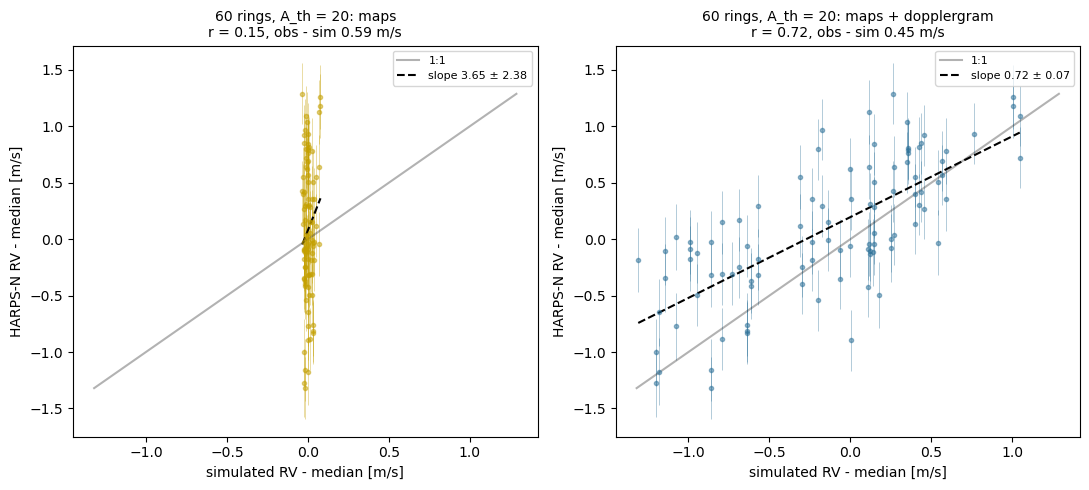

In [103]:
# linear correlation of the RV of the day: HARPS-N against the simulations at 60 rings, A_th = 20 (median of the day removed)
names = ['60 rings, A_th = 20: maps', '60 rings, A_th = 20: maps + dopplergram']
fig, axes = plt.subplots(1, len(names), figsize=(5.5 * len(names), 5), squeeze=False)
for ax, name in zip(axes[0], names):
    c = cmp_day['rv'][name]
    r, k, k_err = fit_line(c['sim'], c['obs'])
    ax.errorbar(c['sim'], c['obs'], yerr=c['obs_err'], fmt='o', ms=3, color=test_colours[name], alpha=0.5, lw=0.5)
    lim = np.array([min(c['sim'].min(), c['obs'].min()), max(c['sim'].max(), c['obs'].max())])
    ax.plot(lim, lim, 'k-', alpha=0.3, label='1:1')
    xs = np.array([c['sim'].min(), c['sim'].max()])
    ax.plot(xs, np.mean(c['obs']) + k * (xs - np.mean(c['sim'])), '--', color='k', label='slope %.2f ± %.2f' % (k, k_err))
    ax.set_title('%s\nr = %.2f, obs - sim %.2f m/s' % (name, r, c['rms']), fontsize=10)
    ax.set_xlabel('simulated RV - median [m/s]')
    ax.set_ylabel('HARPS-N RV - median [m/s]')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

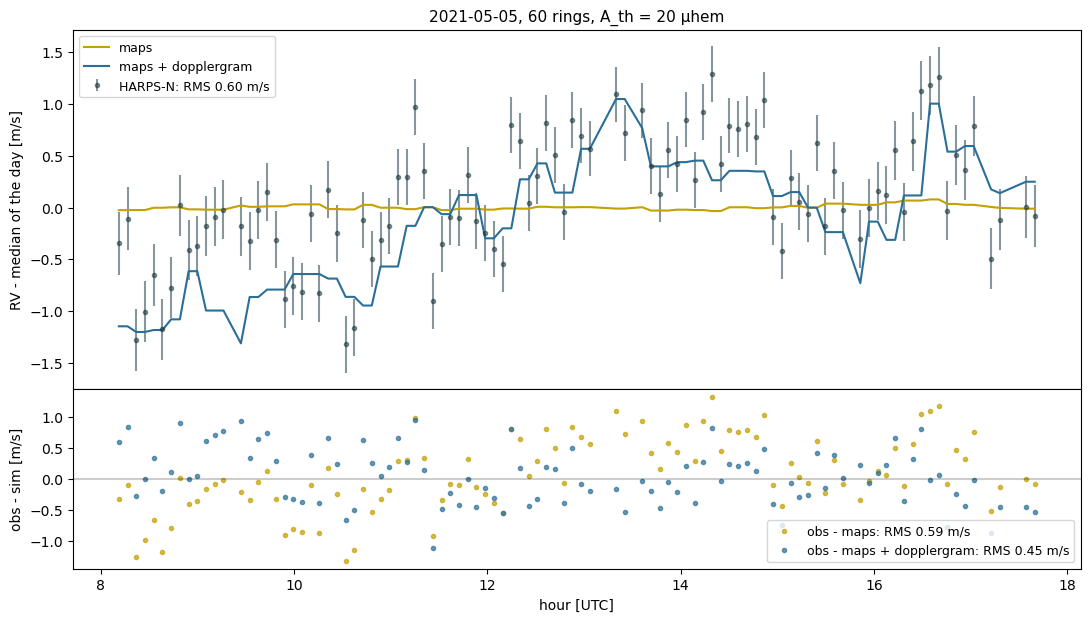

In [104]:
# RV of the day: HARPS-N and the simulations at 60 rings, A_th = 20 (median of the day removed), and the residuals
names = ['60 rings, A_th = 20: maps', '60 rings, A_th = 20: maps + dopplergram']
c = cmp_day['rv'][names[0]]
h = (c['t'] - d_test) * 24
fig, (ax, ar) = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1], 'hspace': 0})
ax.errorbar(h, c['obs'], yerr=c['obs_err'], fmt='o', ms=3, color='#102e37', alpha=0.5,
            label='HARPS-N: RMS %.2f m/s' % c['rms_obs'])
for name in names:
    cc = cmp_day['rv'][name]
    ax.plot(h, cc['sim'], '-', color=test_colours[name], lw=1.5, label=name.split(': ')[1])
    ar.plot(h, cc['res'], 'o', ms=3, color=test_colours[name], alpha=0.7,
            label='obs - %s: RMS %.2f m/s' % (name.split(': ')[1], cc['rms']))
ar.axhline(0, color='k', alpha=0.2)
ax.set_ylabel('RV - median of the day [m/s]')
ax.set_title('%s, 60 rings, A_th = 20 µhem' % TEST_DAY, fontsize=11)
ax.legend(fontsize=9)
ar.set_ylabel('obs - sim [m/s]')
ar.set_xlabel('hour [UTC]')
ar.legend(fontsize=9)
plt.show()

## 8. The same test on 2021-05-31

Section 7 again for the third day (`TEST_DAY = '2021-05-31'`): its SDO epochs processed at full resolution for 60 rings with A_th = 20 µhem (network = quiet photosphere) and A_th = 0 (all the network = faculae), the simulations of every exposure of the day, and the same comparisons with HARPS-N. The variables of section 7 (`sims_day`, `cmp_day`, `test_table`, ...) are replaced by those of this day; the products are in `OUT/test_2021-05-31_N60/`.

In [105]:
TEST_DAY = '2021-05-31'
TEST_RINGS = 60
TEST_CASES = {'A_th = 20': ('Ath20', dict(THRESHOLDS, A_th=20.0)),          # network = quiet photosphere
              'A_th = 0': ('Ath0', dict(THRESHOLDS, A_th=0.0))}             # all the network = faculae
TEST_DIR = os.path.join(OUT, 'test_%s_N%d' % (TEST_DAY, TEST_RINGS))
for tag, _ in TEST_CASES.values():
    os.makedirs(os.path.join(TEST_DIR, tag), exist_ok=True)
d_test = (pd.Timestamp(TEST_DAY) - pd.Timestamp(START)).days
ep_test = ep[np.floor(ep['t']).astype(int) == d_test].reset_index(drop=True)    # the SDO epochs of the day (section 4)

def test_file(tag, e):
    return os.path.join(TEST_DIR, tag, re.sub(r'[^0-9]', '', e['continuum'])[:14] + '.npz')

todo_t = [e for e in ep_test.to_dict('records') if not all(os.path.exists(test_file(tag, e)) for tag, _ in TEST_CASES.values())]
print('%s: %d epochs, %d to do (~%.1f GB, deleted after every epoch)' % (TEST_DAY, len(ep_test), len(todo_t), len(todo_t) * 0.05))
FITS_T = tempfile.mkdtemp(prefix='hmi_test_')
t_start = time.time()
for k, (e, files) in enumerate(sg.prefetch(todo_t, lambda e: sg.fetch_epoch(e, FITS_T), workers=1, ahead=1), 1):
    if isinstance(files, Exception):
        print('[%d/%d] %s: download failed (%s), skipped' % (k, len(todo_t), e['continuum'], str(files)[:100]))
        continue
    try:
        for case, (tag, th) in TEST_CASES.items():
            if os.path.exists(test_file(tag, e)):
                continue
            r = sg.process_epoch(files, size=SIZE, n_rings=TEST_RINGS, thresholds=th)
            np.savez(test_file(tag, e), ff_sp=r['ff_sp'], ff_fc=r['ff_fc'], v_cell=r['v_cell'], w_cell=r['w_cell'],
                     rotation=r['rotation'], obs_vr=r['obs_vr'], ff_sp_disc=r['ff_sp_disc'], ff_fc_disc=r['ff_fc_disc'],
                     ff_nt_disc=r['ff_nt_disc'], t=e['t'], t_rec=e['continuum'])
            del r
    except Exception as err:
        print('[%d/%d] %s: not processed (%s)' % (k, len(todo_t), e['continuum'], str(err)[:100]))
    finally:
        if not KEEP_FITS:
            for p, _ in files.values():
                os.remove(p)
    if k % 5 == 0 or k == len(todo_t):
        el = time.time() - t_start
        print('[%d/%d] %s  %.0f s, ~%.0f min left' % (k, len(todo_t), e['continuum'], el, el / k * (len(todo_t) - k) / 60))
if not KEEP_FITS:
    shutil.rmtree(FITS_T, ignore_errors=True)

2021-05-31: 49 epochs, 0 to do (~0.0 GB, deleted after every epoch)


A_th = 20: faculae 1.02 % of the disc (network not in them: 5.31 %)
A_th = 0: faculae 6.33 % of the disc (network not in them: 0.00 %)


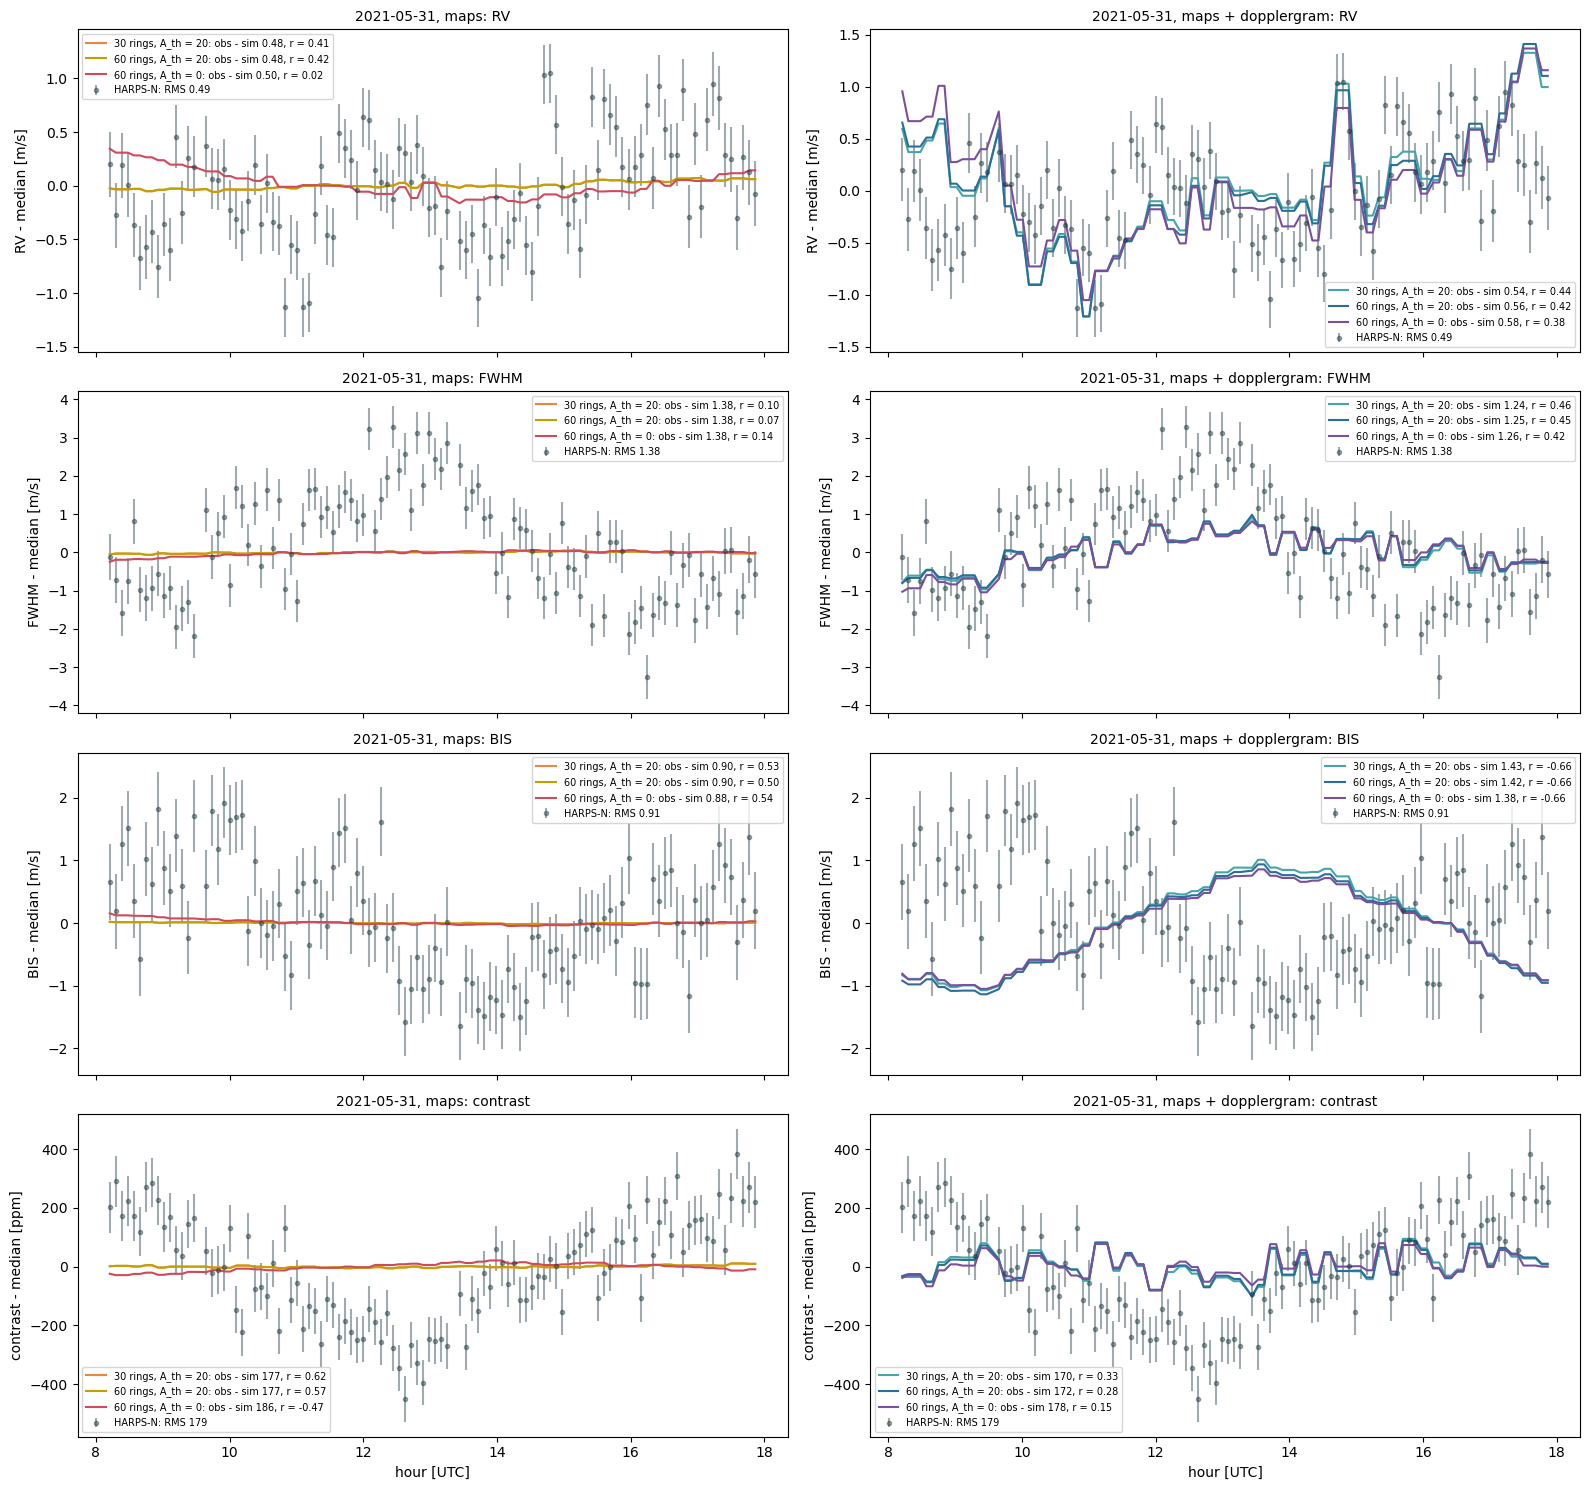

RMS obs  RMS obs - sim  \
quantity model                                                             
rv       30 rings, A_th = 20: maps                  0.492          0.479   
         30 rings, A_th = 20: maps + dopplergram    0.492          0.543   
         60 rings, A_th = 20: maps                  0.492          0.478   
         60 rings, A_th = 20: maps + dopplergram    0.492          0.564   
         60 rings, A_th = 0: maps                   0.492          0.504   
         60 rings, A_th = 0: maps + dopplergram     0.492          0.585   
fwhm     30 rings, A_th = 20: maps                  1.384          1.382   
         30 rings, A_th = 20: maps + dopplergram    1.384          1.242   
         60 rings, A_th = 20: maps                  1.384          1.383   
         60 rings, A_th = 20: maps + dopplergram    1.384          1.251   
         60 rings, A_th = 0: maps                   1.384          1.376   
         60 rings, A_th = 0: maps + dopplergram     1.384          1.260   
bis      30 rings, A_th = 20: maps                  0.905          0.900   
         30 rings, A_th = 20: maps + dopplergram    0.905          1.428   
         60 rings, A_th = 20: maps                  0.905          0.901   
         60 rings, A_th = 20: maps + dopplergram    0.905          1.422   
         60 rings, A_th = 0: maps                   0.905          0.882   
         60 rings, A_th = 0: maps + dopplergram     0.905          1.381   
contrast 30 rings, A_th = 20: maps                179.326        176.945   
         30 rings, A_th = 20: maps + dopplergram  179.326        169.914   
         60 rings, A_th = 20: maps                179.326        177.257   
         60 rings, A_th = 20: maps + dopplergram  179.326        172.062   
         60 rings, A_th = 0: maps                 179.326        185.700   
         60 rings, A_th = 0: maps + dopplergram   179.326        177.848   

                                                      r   slope  slope_err  \
quantity model                                                               
rv       30 rings, A_th = 20: maps                0.409   5.812      1.273   
         30 rings, A_th = 20: maps + dopplergram  0.438   0.405      0.081   
         60 rings, A_th = 20: maps                0.416   5.918      1.270   
         60 rings, A_th = 20: maps + dopplergram  0.424   0.376      0.079   
         60 rings, A_th = 0: maps                 0.020   0.079      0.395   
         60 rings, A_th = 0: maps + dopplergram   0.378   0.336      0.081   
fwhm     30 rings, A_th = 20: maps                0.102   5.791      5.525   
         30 rings, A_th = 20: maps + dopplergram  0.461   1.419      0.267   
         60 rings, A_th = 20: maps                0.070   4.233      5.874   
         60 rings, A_th = 20: maps + dopplergram  0.445   1.384      0.273   
         60 rings, A_th = 0: maps                 0.142   2.955      2.013   
         60 rings, A_th = 0: maps + dopplergram   0.422   1.244      0.262   
bis      30 rings, A_th = 20: maps                0.527  44.796      7.078   
         30 rings, A_th = 20: maps + dopplergram -0.665  -0.918      0.101   
         60 rings, A_th = 20: maps                0.501  46.849      7.938   
         60 rings, A_th = 20: maps + dopplergram -0.661  -0.918      0.102   
         60 rings, A_th = 0: maps                 0.538  10.901      1.675   
         60 rings, A_th = 0: maps + dopplergram  -0.662  -0.993      0.110   
contrast 30 rings, A_th = 20: maps                0.622  28.780      3.557   
         30 rings, A_th = 20: maps + dopplergram  0.326   1.239      0.353   
         60 rings, A_th = 20: maps                0.575  28.291      3.950   
         60 rings, A_th = 20: maps + dopplergram  0.283   1.109      0.368   
         60 rings, A_th = 0: maps                -0.469  -6.536      1.208   
         60 rings, A_th = 0: maps + dopplergram   0.150   0.660      0.428   

                                            

In [106]:
# the exposures of the day and their epochs
sel_day = np.floor(hx['t']).astype(int) == d_test                    # among the exposures kept (hx)
row_test = {tr: i for i, tr in enumerate(ep_test['continuum'])}
e_day = np.array([row_test[tr] for tr in exp_trec[keep][sel_day]])
t_day = hx['t'][sel_day]
h_day = {k: v[sel_day] for k, v in hx.items()}

conf60 = re.sub(r'(?m)^n_grid_rings\s*:\s*\d+', 'n_grid_rings : %d' % TEST_RINGS, open(CONF).read())
conf60_file = os.path.join(OUT, 'sun_N%d.conf' % TEST_RINGS)
open(conf60_file, 'w').write(conf60)
amu60 = np.asarray(nbspectra.generate_grid_coordinates_nb(TEST_RINGS)[3])
ring60 = sg.ring_of_cells(TEST_RINGS)

# the simulations at 30 rings (section 5) on the exposures of the day
sims_day = {'30 rings, A_th = 20: maps': {q: sims_exp['maps'][q][sel_day] for q in observables},
            '30 rings, A_th = 20: maps + dopplergram': {q: sims_exp['maps + dopplergram'][q][sel_day] for q in observables}}
disc_ff = {}
grids60 = None
for case, (tag, _) in TEST_CASES.items():
    prod = [np.load(test_file(tag, e)) for e in ep_test.to_dict('records')]
    a = {k: np.array([p[k] for p in prod]) for k in ('ff_sp', 'ff_fc', 'v_cell', 'w_cell', 'rotation', 'obs_vr',
                                                      'ff_fc_disc', 'ff_nt_disc')}
    disc_ff[case] = (a['ff_fc_disc'].mean(), a['ff_nt_disc'].mean())
    nod = ~np.isfinite(a['v_cell'])
    v1, _ = sg.rescale_by_rotation(a['v_cell'], a['rotation'][:, 0])
    v2, _ = sg.remove_large_scale(v1, a['w_cell'], TEST_RINGS, terms=('ns',))
    v3, _ = sg.remove_ring_profile(v2, a['w_cell'], TEST_RINGS)
    v4 = v3 - np.polyval(vr_coef, a['obs_vr'])[:, None]                 # the polynomial of OBS_VR of 4.1
    v4[nod] = 0.0
    ff = precomputed_filling_factors(t_day, a['ff_sp'][e_day], a['ff_fc'][e_day], TEST_RINGS)
    s = simulate_old_config(conf60_file, times=t_day, observables=observables, paths=PATHS, grids=grids60,
                            active_regions_mask=ff, verbose=False)
    grids60 = s['grids']
    sims_day['60 rings, %s: maps' % case] = {q: s[q] for q in observables}
    s = simulate_old_config(conf60_file, times=t_day, observables=observables, paths=PATHS, grids=grids60,
                            active_regions_mask=ff, verbose=False,
                            quiet_velocity=sg.quiet_velocity_field(t_day, v4[e_day], TEST_RINGS))
    sims_day['60 rings, %s: maps + dopplergram' % case] = {q: s[q] for q in observables}
for case, (fc, nt) in disc_ff.items():
    print('%s: faculae %.2f %% of the disc (network not in them: %.2f %%)' % (case, fc, nt))

# comparison with HARPS-N (the day only: median of the day removed); contrast in ppm of its median
rows, cmp_day = [], {}
for q in ('rv', 'fwhm', 'bis', 'contrast'):
    cmp_day[q] = {}
    for name, sq in sims_day.items():
        y = relative_ppm(sq[q]) if q == 'contrast' else sq[q]
        c = obs.compare_rv_exposures(h_day, y, quantity=q)
        cmp_day[q][name] = c
        r, k, k_err = fit_line(c['sim'], c['obs'])
        rows.append({'quantity': q, 'model': name, 'RMS obs': c['rms_obs'], 'RMS obs - sim': c['rms'], 'r': r,
                     'slope': k, 'slope_err': k_err, 'sim std': np.std(c['sim'])})
test_table = pd.DataFrame(rows)
test_table.to_csv(os.path.join(TEST_DIR, 'statistics.csv'), index=False)

test_colours = {'30 rings, A_th = 20: maps': '#ea8642', '30 rings, A_th = 20: maps + dopplergram': '#45a5aa',
                '60 rings, A_th = 20: maps': '#c4a000', '60 rings, A_th = 20: maps + dopplergram': '#2a6f97',
                '60 rings, A_th = 0: maps': '#d1495b', '60 rings, A_th = 0: maps + dopplergram': '#7b4fa0'}
fig, axes = plt.subplots(4, 2, figsize=(16, 15), sharex=True, squeeze=False)
for row, q in zip(axes, ('rv', 'fwhm', 'bis', 'contrast')):
    label, unit, fmt = UNITS[q]
    for ax, kind in zip(row, ('maps', 'maps + dopplergram')):
        names = [n for n in sims_day if n.endswith(': ' + kind)]
        c = cmp_day[q][names[0]]
        h = (c['t'] - d_test) * 24
        ax.errorbar(h, c['obs'], yerr=c['obs_err'], fmt='o', ms=3, color='#102e37', alpha=0.4,
                    label=('HARPS-N: RMS ' + fmt) % c['rms_obs'])
        for n in names:
            cc = cmp_day[q][n]
            ax.plot(h, cc['sim'], '-', color=test_colours[n], label=('%s: obs - sim ' + fmt + ', r = %.2f')
                    % (n.split(':')[0], cc['rms'], np.corrcoef(cc['obs'], cc['sim'])[0, 1]))
        ax.set_ylabel('%s - median [%s]' % (label, unit))
        ax.set_title('%s, %s: %s' % (TEST_DAY, kind, label), fontsize=10)
        ax.legend(fontsize=7)
for ax in axes[-1]:
    ax.set_xlabel('hour [UTC]')
plt.tight_layout()
plt.show()
test_table.set_index(['quantity', 'model']).round(3)

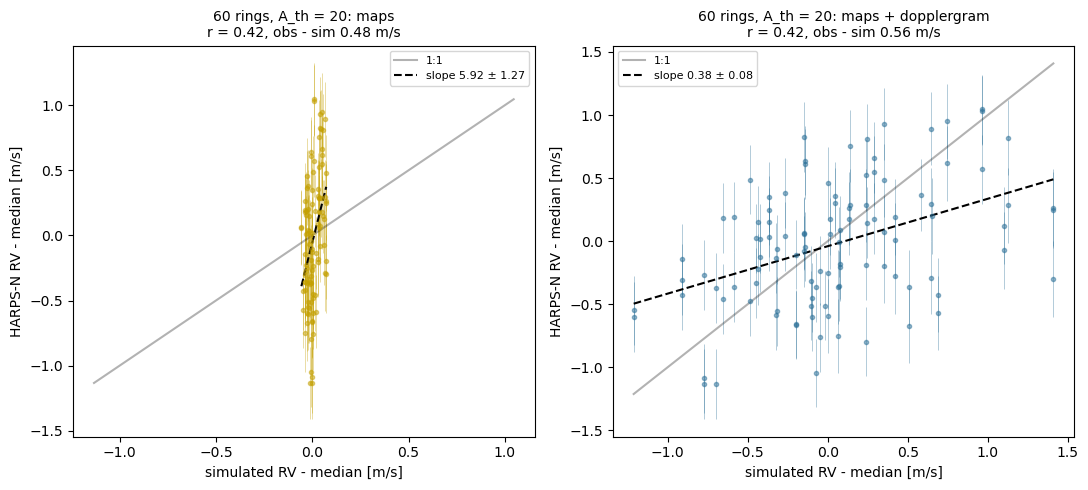

In [107]:
# linear correlation of the RV of the day: HARPS-N against the simulations at 60 rings, A_th = 20 (median of the day removed)
names = ['60 rings, A_th = 20: maps', '60 rings, A_th = 20: maps + dopplergram']
fig, axes = plt.subplots(1, len(names), figsize=(5.5 * len(names), 5), squeeze=False)
for ax, name in zip(axes[0], names):
    c = cmp_day['rv'][name]
    r, k, k_err = fit_line(c['sim'], c['obs'])
    ax.errorbar(c['sim'], c['obs'], yerr=c['obs_err'], fmt='o', ms=3, color=test_colours[name], alpha=0.5, lw=0.5)
    lim = np.array([min(c['sim'].min(), c['obs'].min()), max(c['sim'].max(), c['obs'].max())])
    ax.plot(lim, lim, 'k-', alpha=0.3, label='1:1')
    xs = np.array([c['sim'].min(), c['sim'].max()])
    ax.plot(xs, np.mean(c['obs']) + k * (xs - np.mean(c['sim'])), '--', color='k', label='slope %.2f ± %.2f' % (k, k_err))
    ax.set_title('%s\nr = %.2f, obs - sim %.2f m/s' % (name, r, c['rms']), fontsize=10)
    ax.set_xlabel('simulated RV - median [m/s]')
    ax.set_ylabel('HARPS-N RV - median [m/s]')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

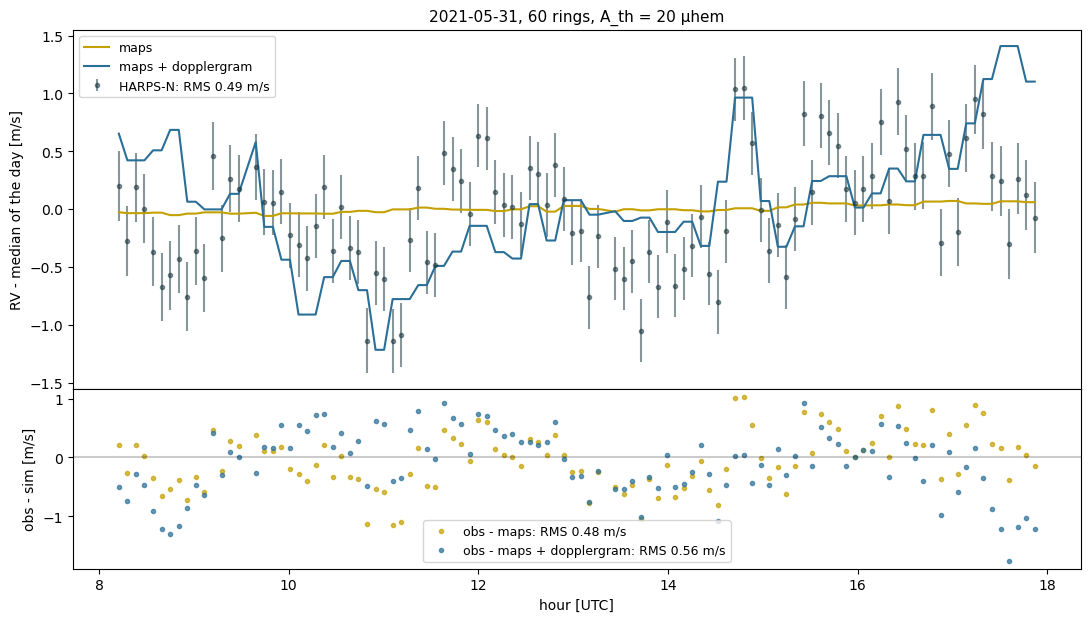

In [108]:
# RV of the day: HARPS-N and the simulations at 60 rings, A_th = 20 (median of the day removed), and the residuals
names = ['60 rings, A_th = 20: maps', '60 rings, A_th = 20: maps + dopplergram']
c = cmp_day['rv'][names[0]]
h = (c['t'] - d_test) * 24
fig, (ax, ar) = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1], 'hspace': 0})
ax.errorbar(h, c['obs'], yerr=c['obs_err'], fmt='o', ms=3, color='#102e37', alpha=0.5,
            label='HARPS-N: RMS %.2f m/s' % c['rms_obs'])
for name in names:
    cc = cmp_day['rv'][name]
    ax.plot(h, cc['sim'], '-', color=test_colours[name], lw=1.5, label=name.split(': ')[1])
    ar.plot(h, cc['res'], 'o', ms=3, color=test_colours[name], alpha=0.7,
            label='obs - %s: RMS %.2f m/s' % (name.split(': ')[1], cc['rms']))
ar.axhline(0, color='k', alpha=0.2)
ax.set_ylabel('RV - median of the day [m/s]')
ax.set_title('%s, 60 rings, A_th = 20 µhem' % TEST_DAY, fontsize=11)
ax.legend(fontsize=9)
ar.set_ylabel('obs - sim [m/s]')
ar.set_xlabel('hour [UTC]')
ar.legend(fontsize=9)
plt.show()